# Import và đọc ảnh

In [77]:
import pandas as pd
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Dense, Dropout, Flatten, Reshape, BatchNormalization
from keras.models import Model
from keras.callbacks import EarlyStopping
from keras.regularizers import l2
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [78]:
# # Hàm đọc ảnh từ những split cho vào
# # Trả về ảnh và nhãn tương ứng dưới dạng: ma trận [số ảnh, 64, 64] và ma trận nồng độ [số ảnh,2]
# def read_img_from_splits(df, split_list, folder):
#     # Chỉ lấy các dòng thuộc list split đã chọn
#     df_part = df[df['split_number'].isin(split_list)]
#     images = []

#     # Lặp qua từng hàng trong dataframe để đọc ảnh và lấy nhãn tương ứng 
#     for index, row in df_part.iterrows():
#         img_path = folder + '/split' + str(row['split_number']) + '/' + str(row['image_name'])
#         img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Đọc ảnh xám
#         img = np.array(img).astype('float32') / 255.0  # Chuẩn hóa dữ liệu ảnh
#         images.append(img)

#     # Chuyển đổi danh sách thành numpy arrays
#     df_part.loc[:,["Image"]] = images
#     images = np.array(images)
    
#     return images, df_part[["Ethanol","Acetone","Methanol"]], df_part

import ast
import cv2
import numpy as np
import pandas as pd

def has_sensor_failure(abnormal_detail):
    if pd.isna(abnormal_detail):
        return False
    if isinstance(abnormal_detail, str):
        abnormal_detail = ast.literal_eval(abnormal_detail)
    if not isinstance(abnormal_detail, dict):
        return False
    return abnormal_detail.get("Sensor Failure", 0) > 0
    
def read_img_from_splits(
    df,
    split_list,
    folder,
    exclude_sensor_failure=False
):
    df_part = (
        df[df["split_number"].isin(split_list)]
        .copy()
        .reset_index(drop=True)
    )
    # loại mọi ảnh có Sensor Failure trong abnormal_detail
    if (
        exclude_sensor_failure
        and "abnormal_detail" in df_part.columns
    ):
        mask = ~df_part["abnormal_detail"].apply(
            has_sensor_failure
        )
        print(
            f"Removed {(~mask).sum()} images "
            f"containing Sensor Failure"
        )
        df_part = (
            df_part[mask]
            .copy()
            .reset_index(drop=True)
        )
    images = []
    for _, row in df_part.iterrows():
        img_path = (
            f"{folder}/split{row['split_number']}/"
            f"{row['image_name']}"
        )
        img = cv2.imread(
            img_path,
            cv2.IMREAD_GRAYSCALE
        )
        img = img.astype(np.float32) / 255.0
        images.append(img)
    df_part["Image"] = images
    images = np.stack(images)
    return (
        images,
        df_part[["Ethanol","Acetone","Methanol"]],
        df_part
    )
    

            
def extract_xy_keep_normal(
    df,
    abnormal_ratio=0.3,
    random_state=42,
    keep_all_abnormal=False
):
    """
    Giữ toàn bộ normal.

    keep_all_abnormal=True:
        Giữ toàn bộ abnormal.

    keep_all_abnormal=False:
        Sample abnormal theo tỷ lệ abnormal_ratio.
    """

    df = df.copy()
    df["is_abnormal"] = 1 - df["is_normal"]

    df_normal = df[df["is_abnormal"] == 0]
    df_ab = df[df["is_abnormal"] == 1]

    # ==========================
    # Giữ toàn bộ abnormal
    # ==========================
    if keep_all_abnormal:
        df_balanced = pd.concat(
            [df_normal, df_ab],
            ignore_index=True
        )

    else:

        n_normal = len(df_normal)

        if abnormal_ratio == 0:
            n_ab_sample = 0

        elif abnormal_ratio == 1:
            n_ab_sample = len(df_ab)

        else:
            n_ab_sample = int(
                n_normal * abnormal_ratio / (1 - abnormal_ratio)
            )

        if len(df_ab) > 0:

            df_ab_sampled = df_ab.sample(
                n=min(n_ab_sample, len(df_ab)),
                random_state=random_state
            )

            df_balanced = pd.concat(
                [df_normal, df_ab_sampled],
                ignore_index=True
            )

        else:
            df_balanced = df_normal.copy()

    # ==========================
    # Extract
    # ==========================

    X = np.array(df_balanced["Image"].tolist())
    X = np.expand_dims(X, axis=-1)

    y = df_balanced["is_abnormal"].to_numpy()

    df_balanced = df_balanced.copy()
    df_balanced["Image"] = list(X)

    return X, y, df_balanced

In [79]:
dataset_path = "/kaggle/input/datasets/dangthithuha/voc-t7-pl"
exclude_sensor_failure = False
abnormal_ratio = 0.2

df_aug_ab = pd.read_csv(f'{dataset_path}/augmented_abnormal_gen/image_labels.csv')
df_aug = pd.read_csv(f'{dataset_path}/augmented/image_labels.csv')
df_ab_raw = pd.read_csv(f'{dataset_path}/augmented_abnormal_raw/image_labels.csv')

split_test = [1]
split_val = [2]
split_train = [i for i in range(1,6) if i not in split_test and i not in split_val] 

# Đọc các ảnh bình thường, cho split 1 2 3 4 là x_train
# Đọc split 5 mục abnormal để thành x_test_abnormal, mục normal làm x_test_normal
_, _, df_train = read_img_from_splits(df_aug_ab, split_train, folder=f"{dataset_path}/augmented_abnormal_gen",
                                     exclude_sensor_failure=exclude_sensor_failure)
_, _, df_val = read_img_from_splits(df_aug_ab, split_val, folder=f"{dataset_path}/augmented_abnormal_gen",
                                     exclude_sensor_failure=exclude_sensor_failure)
_, _, df_test = read_img_from_splits(df_aug, split_test, folder=f"{dataset_path}/augmented",
                                    exclude_sensor_failure=exclude_sensor_failure)
df_test['is_normal'] = 1
df_test['severity'] = 0

_, _, df_test_ab_raw = read_img_from_splits(df_ab_raw, [1,2,3,4,5], folder=f"{dataset_path}/augmented_abnormal_raw",
                                           exclude_sensor_failure=exclude_sensor_failure)
df_test_ab_raw['is_normal'] = 0
df_test_ab_raw['severity'] = 1
df_test = pd.concat([df_test, df_test_ab_raw])

# ===== Train =====
X_train, y_train, df_train = extract_xy_keep_normal(
    df_train,
    abnormal_ratio=abnormal_ratio
)
# ===== Val =====
X_val, y_val, df_val = extract_xy_keep_normal(
    df_val,
    abnormal_ratio=abnormal_ratio
)
# ===== Test =====
X_test, y_test, df_test = extract_xy_keep_normal(
    df_test,
    keep_all_abnormal=True
)

print("Train shape:", X_train.shape, y_train.shape)
print("Val shape:", X_val.shape, y_val.shape)
print("Test shape :", X_test.shape, y_test.shape)

print("\nSample train y:", y_train[:10])
print("\nSample val y:", y_val[:10])
print("Sample test y :", y_test[:10])

# distribution
def print_dist(y, name):
    unique, counts = np.unique(y, return_counts=True)
    print(f"{name} distribution:", dict(zip(unique, counts)))

print_dist(y_train, "Train")
print_dist(y_val, "Val")
print_dist(y_test, "Test")

# Huấn luyện mô hình Autoencoder
X_train_normal = X_train[y_train == 0]
X_val_normal = X_val[y_val == 0]
X_test_normal = X_test[y_test == 0]
print(len(X_train_normal))
print(df_train[df_train.is_abnormal==0].shape)
print(df_train["dominant_abnormal"].value_counts())

print(df_test[df_test.is_abnormal==0].shape)
print(df_test["dominant_abnormal"].value_counts())

Train shape: (675, 128, 128, 1) (675,)
Val shape: (227, 128, 128, 1) (227,)
Test shape : (310, 128, 128, 1) (310,)

Sample train y: [0 0 0 0 0 0 0 0 0 0]

Sample val y: [0 0 0 0 0 0 0 0 0 0]
Sample test y : [0 0 0 0 0 0 0 0 0 0]
Train distribution: {np.int64(0): np.int64(540), np.int64(1): np.int64(135)}
Val distribution: {np.int64(0): np.int64(182), np.int64(1): np.int64(45)}
Test distribution: {np.int64(0): np.int64(182), np.int64(1): np.int64(128)}
540
(540, 11)
dominant_abnormal
Sensor Failure    34
Signal Drift      32
Noise             28
Random Patch      21
Abrupt Change     20
Name: count, dtype: int64
(182, 11)
dominant_abnormal
Random Patch      28
Noise             26
Abrupt Change     22
Signal Drift      20
Sensor Failure    20
Unknown Gas       12
Name: count, dtype: int64


In [80]:
print("TRAIN split 3,4,5")
print(df_train.shape)
print(df_train["is_abnormal"].value_counts())


print("VAL split 2")
print(df_val.shape)
print(df_val["is_abnormal"].value_counts())


print("TEST")
print(df_test.shape)
print(df_test["is_abnormal"].value_counts())
# Lấy riêng train normal
df_train_normal = df_train[df_train["is_abnormal"] == 0].copy()

print(df_train_normal.shape)
print(df_train_normal["is_abnormal"].value_counts())
print("==============")
X_train_normal = X_train[y_train == 0]
X_val_normal = X_val[y_val == 0]
X_test_normal = X_test[y_test == 0]
print(X_test.shape)
print(X_train.shape)

print("******************")
X_test_moi=X_test
print(X_test_moi.shape)
X_train_moi=X_train[y_train == 0]
print( X_train_moi.shape)


TRAIN split 3,4,5
(675, 11)
is_abnormal
0    540
1    135
Name: count, dtype: int64
VAL split 2
(227, 11)
is_abnormal
0    182
1     45
Name: count, dtype: int64
TEST
(310, 11)
is_abnormal
0    182
1    128
Name: count, dtype: int64
(540, 11)
is_abnormal
0    540
Name: count, dtype: int64
(310, 128, 128, 1)
(675, 128, 128, 1)
******************
(310, 128, 128, 1)
(540, 128, 128, 1)


Có 245 ảnh,68 hỗn hợp nồng độ khác nhau

# Sắp xếp ảnh

### Normal

In [4]:
# import matplotlib.pyplot as plt
# import math

# # Số cột mong muốn trong lưới hiển thị
# columns = 5

# # Tạo danh sách chứa tổng nồng độ (CO2 + Ethylene) và chỉ số ảnh từ tập x_normal
# image_data_normal = [(x_normal[i], y_normal_co2[i], y_normal_ethylene[i], y_normal_co2[i] + y_normal_ethylene[i]) 
#                      for i in range(len(x_normal))]

# # Sắp xếp danh sách dựa theo tổng nồng độ (CO2 + Ethylene)
# image_data_sorted = sorted(image_data_normal, key=lambda x: x[3])  # Sắp xếp theo tổng nồng độ

# # Hiển thị ảnh theo thứ tự đã sắp xếp
# num_images = len(image_data_sorted)
# rows = math.ceil(num_images / columns)  # Tính số hàng cần thiết dựa trên số cột

# plt.figure(figsize=(15, rows * 3))  # Kích thước figure tổng thể
# for i in range(num_images):
#     image, co2, ethylene, total_concentration = image_data_sorted[i]
#     plt.subplot(rows, columns, i + 1)  # Tạo các lưới con
#     plt.imshow(image.squeeze(), cmap='gray')  # Hiển thị ảnh
#     plt.axis('off')  # Tắt trục tọa độ
#     plt.title(f"CO2: {co2:.1f} ppm\nEthylene: {ethylene:.1f} ppm\nTotal: {total_concentration:.1f} ppm")  # Hiển thị CO2, Ethylene và tổng nồng độ

# plt.tight_layout()  # Sắp xếp gọn các ảnh
# plt.show()

### Abnomal

In [5]:
# import matplotlib.pyplot as plt
# import math

# # Số cột mong muốn trong lưới hiển thị
# columns = 5

# # Tạo danh sách chứa tổng nồng độ (CO2 + Ethylene) và chỉ số ảnh từ tập x_test_abnormal
# image_data_abnormal = [(x_test_abnormal[i], y_abnormal_co2[i], y_abnormal_ethylene[i], y_abnormal_co2[i] + y_abnormal_ethylene[i]) 
#                        for i in range(len(x_test_abnormal))]

# # Sắp xếp danh sách dựa theo tổng nồng độ (CO2 + Ethylene)
# image_data_sorted_abnormal = sorted(image_data_abnormal, key=lambda x: x[3])  # Sắp xếp theo tổng nồng độ

# # Hiển thị ảnh theo thứ tự đã sắp xếp
# num_images = len(image_data_sorted_abnormal)
# rows = math.ceil(num_images / columns)  # Tính số hàng cần thiết dựa trên số cột

# plt.figure(figsize=(15, rows * 3))  # Kích thước figure tổng thể
# for i in range(num_images):
#     image, co2, ethylene, total_concentration = image_data_sorted_abnormal[i]
#     plt.subplot(rows, columns, i + 1)  # Tạo các lưới con
#     plt.imshow(image.squeeze(), cmap='gray')  # Hiển thị ảnh
#     plt.axis('off')  # Tắt trục tọa độ
#     plt.title(f"CO2: {co2:.1f} ppm\nEthylene: {ethylene:.1f} ppm\nTotal: {total_concentration:.1f} ppm")  # Hiển thị CO2, Ethylene và tổng nồng độ

# plt.tight_layout()  # Sắp xếp gọn các ảnh
# plt.show()

In [6]:
# import matplotlib.pyplot as plt
# import math

# # Số cột mong muốn trong lưới hiển thị
# columns = 5

# # Hiển thị toàn bộ ảnh từ tập huấn luyện (CO2 < 300)
# num_images = len(x_train)
# rows = math.ceil(num_images / columns)  # Tính số hàng cần thiết dựa trên số cột

# plt.figure(figsize=(15, rows * 3))  # Kích thước figure tổng thể
# for i in range(num_images):
#     plt.subplot(rows, columns, i + 1)  # Tạo các lưới con
#     plt.imshow(x_train[i].squeeze(), cmap='gray')  # Hiển thị ảnh, squeeze để loại bỏ chiều đơn lẻ
#     plt.axis('off')  # Tắt trục tọa độ
#     plt.title(f"CO2: {y_train_co2[i]:.1f} ppm\nEthylene: {y_train_ethylene[i]:.1f} ppm")  # Hiển thị CO2 và Ethylene

# plt.tight_layout()  # Sắp xếp gọn các ảnh
# plt.show()

# # Hiển thị toàn bộ ảnh từ tập abnormal (CO2 >= 300)
# num_images = len(x_test_abnormal)
# rows = math.ceil(num_images / columns)  # Tính số hàng cần thiết dựa trên số cột

# plt.figure(figsize=(15, rows * 3))  # Kích thước figure tổng thể
# for i in range(num_images):
#     plt.subplot(rows, columns, i + 1)  # Tạo các lưới con
#     plt.imshow(x_test_abnormal[i].squeeze(), cmap='gray')  # Hiển thị ảnh
#     plt.axis('off')  # Tắt trục tọa độ
#     plt.title(f"CO2: {y_abnormal_co2[i]:.1f} ppm\nEthylene: {y_abnormal_ethylene[i]:.1f} ppm")  # Hiển thị CO2 và Ethylene

# plt.tight_layout()  # Sắp xếp gọn các ảnh
# plt.show()

# Model

In [81]:
%%time
# Kích thước:
input_img = Input(shape=(128, 128, 1))  # Đầu vào ảnh có kích thước 128x128
stride = 2

# Encoder
x = Conv2D(32, (5, 5), activation='relu', padding='same', strides=stride)(input_img)  # tensor 64x64x128
x = Conv2D(16, (5, 5), activation='relu', padding='same', strides=stride)(x)  # tensor 32x32x64
x = Conv2D(8, (5, 5), activation='relu', padding='same', strides=stride)(x)  # tensor 16x16x32
x = Conv2D(8, (5, 5), activation='relu', padding='same', strides=stride)(x)  # tensor 16x16x32
x = MaxPooling2D((2, 2), padding='same')(x)  # tensor 8x8x32 (giảm kích thước với MaxPooling)
x = Flatten()(x)  # Vector 1D tensor với 8*8*32=2048 phần tử

# Tạo mô hình Encoder
encoder = Model(input_img, x)

# Decoder
x = Reshape((4, 4, 8))(x)  # Chuyển đổi từ vector 1D thành tensor 3D

x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
x = Conv2D(8, (5, 5), activation='relu', padding='same')(x)  # tensor 32x32x32

x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
x = Conv2D(8, (5, 5), activation='relu', padding='same')(x)  # tensor 32x32x32
x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
x = Conv2D(16, (5, 5), activation='relu', padding='same')(x)  # tensor 64x64x64
x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
x = Conv2D(32, (5, 5), activation='relu', padding='same')(x)  # tensor 128x128x128
x = UpSampling2D((2, 2))(x)  # tensor 16x16x32 (tăng kích thước)
decoded = Conv2D(1, (5, 5), activation='sigmoid', padding='same')(x)  # tensor 128x128x1 (kết quả cuối cùng là ảnh 128x128x1)

# Xây dựng mô hình Autoencoder
autoencoder = Model(input_img, decoded)
autoencoder.summary()  # Hiển thị kiến trúc 
autoencoder.compile(optimizer='adam', loss='mse')

callback = EarlyStopping(monitor='loss', patience=30)
autoencoder.fit(X_train_normal, X_train_normal,
                epochs=25,
                batch_size=16,
                shuffle=True,
                validation_data=(X_val_normal, X_val_normal),
                verbose=2,
                callbacks=[callback])

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 64, 64, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 32, 32, 16)     │        12,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 16, 16, 8)      │         3,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 8, 8, 8)        │         1,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 4, 4, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_15 (UpSampling2D) │ (None, 8, 8, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 8, 8, 8)        │         1,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_16 (UpSampling2D) │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 16, 8)      │         1,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_17 (UpSampling2D) │ (None, 32, 32, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 32, 32, 16)     │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_18 (UpSampling2D) │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 64, 64, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_19 (UpSampling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 128, 128, 1)    │           801 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,529 (150.50 KB)

 Trainable params: 38,529 (150.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
34/34 - 30s - 885ms/step - loss: 0.0656 - val_loss: 0.0248
Epoch 2/25
34/34 - 25s - 749ms/step - loss: 0.0145 - val_loss: 0.0103
Epoch 3/25
34/34 - 25s - 738ms/step - loss: 0.0074 - val_loss: 0.0103
Epoch 4/25
34/34 - 25s - 737ms/step - loss: 0.0054 - val_loss: 0.0048
Epoch 5/25
34/34 - 26s - 756ms/step - loss: 0.0043 - val_loss: 0.0042
Epoch 6/25
34/34 - 25s - 749ms/step - loss: 0.0038 - val_loss: 0.0037
Epoch 7/25
34/34 - 25s - 747ms/step - loss: 0.0035 - val_loss: 0.0036
Epoch 8/25
34/34 - 25s - 745ms/step - loss: 0.0032 - val_loss: 0.0037
Epoch 9/25
34/34 - 25s - 740ms/step - loss: 0.0030 - val_loss: 0.0033
Epoch 10/25
34/34 - 25s - 739ms/step - loss: 0.0031 - val_loss: 0.0035
Epoch 11/25
34/34 - 25s - 746ms/step - loss: 0.0030 - val_loss: 0.0036
Epoch 12/25
34/34 - 25s - 744ms/step - loss: 0.0026 - val_loss: 0.0034
Epoch 13/25
34/34 - 25s - 747ms/step - loss: 0.0034 - val_loss: 0.0035
Epoch 14/25
34/34 - 26s - 750ms/step - loss: 0.0024 - val_loss: 0.0033
Epoch 15/25
34/

## Evaluate training stage

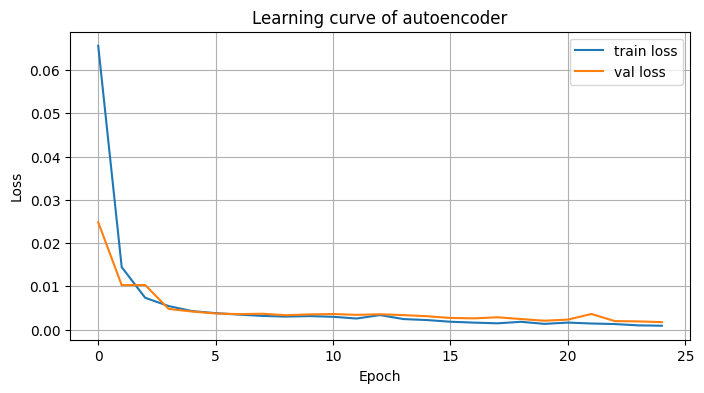

In [82]:
import os
import matplotlib.pyplot as plt
# Tạo thư mục output nếu chưa có
os.makedirs("output", exist_ok=True)
plt.figure(figsize=(8, 4))
plt.plot(autoencoder.history.history['loss'], 
         label="train loss")
plt.plot(autoencoder.history.history['val_loss'], 
         label="val loss")
plt.title("Learning curve of autoencoder")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()
# Lưu ảnh độ phân giải 600 dpi
plt.savefig(
    "output/autoencoder_learning_curve.png",
    dpi=600,
    bbox_inches='tight'
)
plt.close()

## Predict

In [83]:
def create_image_dataframe_from_df(
    model,
    encoder,
    train_df=None,
    val_df=None,
    test_df=None,
    image_col='Image'
):
    """
    Giữ nguyên toàn bộ cột của df gốc.
    Bổ sung:
        original_image
        reconstructed_image
        latent_vector
        partition   (train/val/test)
    """

    dfs = []

    datasets = [
        (train_df, "train"),
        (val_df, "val"),
        (test_df, "test")
    ]
    for df_src, partition in datasets:
        if df_src is None or len(df_src) == 0:
            continue

        df_tmp = df_src.copy()

        X = np.stack(df_tmp[image_col].values)

        print(
            f"Predicting {partition} "
            f"({len(df_tmp)} samples)"
        )

        reconstructed = model.predict(X, verbose=0)
        latent = encoder.predict(X, verbose=0)

        df_tmp["original_image"] = list(X)
        df_tmp["reconstructed_image"] = list(reconstructed)
        df_tmp["latent_vector"] = list(latent)
        df_tmp["partition"] = partition

        dfs.append(df_tmp)

    return pd.concat(dfs, ignore_index=True)

image_df = create_image_dataframe_from_df(
    autoencoder,
    encoder,
    train_df=df_train,
    val_df=df_val,
    test_df=df_test
)
image_df["is_abnormal"] = 1 - image_df["is_normal"]

image_df["True_Label"] = np.where(
    image_df["is_normal"] == 1,
    "Normal",
    "Abnormal"
)

image_df["label"] = np.select(
    [
        (image_df["partition"] == "train") & (image_df["is_normal"] == 1),
        (image_df["partition"] == "train") & (image_df["is_normal"] == 0),

        (image_df["partition"] == "val") & (image_df["is_normal"] == 1),
        (image_df["partition"] == "val") & (image_df["is_normal"] == 0),

        (image_df["partition"] == "test") & (image_df["is_normal"] == 1),
        (image_df["partition"] == "test") & (image_df["is_normal"] == 0),
    ],
    [
        "norm_train",
        "ab_train",

        "norm_val",
        "ab_val",

        "norm_test",
        "ab_test",
    ],
    default="unknown"
)

print(image_df.shape)

print(image_df['dominant_abnormal'].value_counts(dropna=False))
print(len(image_df[image_df['dominant_abnormal'].isna() & (image_df['partition']=="train")]))

Predicting train (675 samples)
Predicting val (227 samples)
Predicting test (310 samples)
(1212, 17)
dominant_abnormal
NaN               904
Sensor Failure     66
Noise              64
Signal Drift       61
Random Patch       57
Abrupt Change      48
Unknown Gas        12
Name: count, dtype: int64
540


## Threshold helpers

In [95]:
# ========================================================================================
# THRESHOLD-BASED ANOMALY DETECTION (CONSOLIDATED)
# ========================================================================================
# Các function gọn gàng, không lặp lại logic:
# 1. compute_error_once: Tính error từ ảnh, xử lý NaN/inf
# 2. run_threshold_experiments: Chạy toàn bộ experiments với nhiều alphas
# 3. evaluate_with_fixed_alpha: Evaluate một error function với alpha cố định
# ========================================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, r2_score, confusion_matrix
)

def compute_error_once(image_df, cal_error_function):
    """
    Tính error một lần từ toàn bộ DataFrame.
    
    ⚠️ QUAN TRỌNG: Xử lý NaN/inf bằng median của BỘ DỮ LIỆU ĐÓ
    Nếu tính error từ subset khác nhau (train vs test), median khác nhau → error khác
    
    Args:
        image_df: DataFrame có 'original_image' và 'reconstructed_image'
        cal_error_function: Hàm tính error (MSE, MADn, MSD)
    
    Returns:
        pd.Series: Error values
    """
    original_images_list = image_df['original_image'].tolist()
    reconstructed_images_list = image_df['reconstructed_image'].tolist()

    errors = cal_error_function(original_images_list, reconstructed_images_list)
    
    # Xử lý inf/nan
    errors = pd.Series(np.array(errors, dtype=np.float64))
    errors.replace([np.inf, -np.inf], np.nan, inplace=True)
    errors = errors.fillna(errors.median())
    
    return errors


def plot_error_distribution(eval_df, thresholds, title="Error Distribution"):
    """
    Vẽ KDE + CDF của error với các đường threshold.
    """
    mean_error = thresholds['mean']
    threshold_min = thresholds['threshold_min']
    threshold_max = thresholds['threshold_max']
    
    unique_labels = eval_df['label'].unique()
    palette = sns.color_palette("tab10", n_colors=len(unique_labels))
    color_map = dict(zip(unique_labels, palette))
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # KDE
    ax_kde = axes[0]
    for label in unique_labels:
        data = eval_df[eval_df['label'] == label]['error']
        sns.kdeplot(data, label=f'KDE ({label})', color=color_map[label], 
                   fill=True, alpha=0.5, ax=ax_kde)
    
    ax_kde.axvline(mean_error, color='g', linestyle='--', linewidth=2, label=f'Mean ({mean_error:.4f})')
    ax_kde.axvline(threshold_min, color='r', linestyle='--', linewidth=2, label=f'Min ({threshold_min:.4f})')
    ax_kde.axvline(threshold_max, color='r', linestyle='--', linewidth=2, label=f'Max ({threshold_max:.4f})')
    ax_kde.set_title(f'{title} - KDE')
    ax_kde.set_xlabel('Error')
    ax_kde.set_ylabel('Density')
    ax_kde.legend(loc='upper right')
    ax_kde.grid(True, alpha=0.6)
    
    # CDF
    ax_cdf = axes[1]
    for label in unique_labels:
        data = eval_df[eval_df['label'] == label]['error']
        sns.ecdfplot(data, label=f'CDF ({label})', color=color_map[label], ax=ax_cdf)
    
    ax_cdf.axvline(mean_error, color='g', linestyle='--', linewidth=2, label=f'Mean ({mean_error:.4f})')
    ax_cdf.axvline(threshold_min, color='r', linestyle='--', linewidth=2, label=f'Min ({threshold_min:.4f})')
    ax_cdf.axvline(threshold_max, color='r', linestyle='--', linewidth=2, label=f'Max ({threshold_max:.4f})')
    ax_cdf.set_title(f'{title} - CDF')
    ax_cdf.set_xlabel('Error')
    ax_cdf.set_ylabel('Cumulative Probability')
    ax_cdf.legend(loc='lower right')
    ax_cdf.grid(True, alpha=0.6)
    
    plt.tight_layout()
    plt.show()


def classify_and_evaluate(df, thresholds, verbose=True):
    """
    Phân loại dữ liệu bằng threshold và tính metrics.
    
    Args:
        df: DataFrame có 'error' và 'True_Label'
        thresholds: Dict chứa threshold_min, threshold_max
        verbose: In kết quả hay không
    
    Returns:
        dict: Metrics (accuracy, f1, precision, recall, r2)
    """
    threshold_min = thresholds['threshold_min']
    threshold_max = thresholds['threshold_max']
    
    # Phân loại
    df['Predicted_Label'] = np.where(
        (df['error'] < threshold_min) | (df['error'] > threshold_max),
        'Abnormal',
        'Normal'
    )
    
    y_true = df['True_Label']
    y_pred = df['Predicted_Label']
    
    # Metrics
    acc = accuracy_score(y_true, y_pred)
    
    metrics = {'accuracy': acc}
    
    if len(np.unique(y_true)) > 1:
        metrics['f1'] = f1_score(y_true, y_pred, pos_label='Abnormal')
        metrics['precision'] = precision_score(y_true, y_pred, pos_label='Abnormal', zero_division=0)
        metrics['recall'] = recall_score(y_true, y_pred, pos_label='Abnormal', zero_division=0)
        
        y_true_bin = (y_true == 'Abnormal').astype(int)
        y_pred_bin = (y_pred == 'Abnormal').astype(int)
        metrics['r2'] = r2_score(y_true_bin, y_pred_bin)
    
    if verbose:
        print("\n" + "=" * 60)
        print("CLASSIFICATION RESULTS")
        print("=" * 60)
        
        cm = confusion_matrix(y_true, y_pred, labels=['Normal', 'Abnormal'])
        print("\nConfusion Matrix:")
        print(pd.DataFrame(cm, 
            index=['True Normal', 'True Abnormal'],
            columns=['Pred Normal', 'Pred Abnormal']))
        
        print("\nClassification Report:")
        print(classification_report(y_true, y_pred, labels=['Normal', 'Abnormal'], zero_division=0))
        
        print("\nMetrics:")
        for k, v in metrics.items():
            print(f"  {k}: {v:.4f}")

    # đánh giá trên từng abnormal type - Hương
        if verbose and 'dominant_abnormal' in df.columns:
        
            print("\n" + "=" * 60)
            print("PER-ABNORMAL PERFORMANCE")
            print("=" * 60)
        
        df['abnormal_group'] = df['dominant_abnormal'].fillna('Normal')
        
        abnormal_rows = []
        
        for abnormal_type in sorted(df['abnormal_group'].unique()):
        
            subset = df[df['abnormal_group'] == abnormal_type]
        
            y_true = subset['True_Label']
            y_pred = subset['Predicted_Label']
        
            # số mẫu đúng và sai
            correct = (y_true == y_pred).sum()
            wrong = (y_true != y_pred).sum()
        
            abnormal_rows.append({
                'dominant_abnormal': abnormal_type,
                'count': len(subset),
        
                'correct': correct,
                'wrong': wrong,
        
                'accuracy': accuracy_score(y_true, y_pred),
        
                'precision': precision_score(
                    (y_true == 'Abnormal').astype(int),
                    (y_pred == 'Abnormal').astype(int),
                    zero_division=0
                ),
        
                'recall': recall_score(
                    (y_true == 'Abnormal').astype(int),
                    (y_pred == 'Abnormal').astype(int),
                    zero_division=0
                ),
        
                'f1_score': f1_score(
                    (y_true == 'Abnormal').astype(int),
                    (y_pred == 'Abnormal').astype(int),
                    zero_division=0
                )
            })
        
        
        abnormal_report = (
            pd.DataFrame(abnormal_rows)
            .sort_values('count', ascending=False)
            .reset_index(drop=True)
        )
        
        
        print(abnormal_report.round(4))
    return metrics, df


def run_threshold_experiments(image_df, error_functions, alphas=np.arange(1.5, 4.5, 0.5)):
    """
    Chạy threshold experiments với multiple error functions và alphas.
    
    Quy trình:
    1. Tính error từ toàn bộ image_df (KHÔNG tính riêng train/test)
    2. Với mỗi error function:
       a. Tính threshold từ norm_train
       b. Evaluate trên val set
    
    Args:
        image_df: DataFrame đầy đủ
        error_functions: Dict {name: function}
        alphas: List các giá trị alpha để thử
    
    Returns:
        pd.DataFrame: Kết quả cho tất cả combinations
    """
    all_results = []
    
    for name, func in error_functions.items():
        print(f"\n{'='*60}")
        print(f"ERROR FUNCTION: {name}")
        print(f"{'='*60}")
        
        # Tính error MỘT LẦN từ toàn bộ image_df
        df_error = image_df.copy()
        df_error['error'] = compute_error_once(image_df, func)
        
        for alpha in alphas:
            # Tính threshold từ norm_train
            norm_train = df_error[df_error['label'] == 'norm_train']['error']
            mean = norm_train.mean()
            std = norm_train.std()
            
            threshold_min = mean - alpha * std
            threshold_max = mean + alpha * std
            
            thresholds = {
                'mean': mean,
                'std': std,
                'threshold_min': threshold_min,
                'threshold_max': threshold_max,
                'alpha': alpha
            }
            
            # Evaluate trên val
            test_df = df_error[df_error['partition'] == "val"].copy()
            metrics, _ = classify_and_evaluate(test_df, thresholds, verbose=False)
            
            result = {
                'error_function': name,
                'alpha': alpha,
                'mean': mean,
                'std': std,
                'threshold_min': threshold_min,
                'threshold_max': threshold_max,
                **metrics
            }
            
            all_results.append(result)
            print(f"  alpha={alpha:.2f} → F1={metrics.get('f1', 0):.4f}, Acc={metrics['accuracy']:.4f}")
    
    results_df = pd.DataFrame(all_results)
    return results_df


def evaluate_with_fixed_alpha(image_df, cal_error_function, alpha, plot=True, verbose=True):
    """
    Evaluate một error function với alpha cố định.
    
    ⚠️ FIX: Tính error từ image_df một lần (KHÔNG tính riêng train/test)
    để median nhất quán với run_threshold_experiments
    
    Args:
        image_df: DataFrame đầy đủ
        cal_error_function: Hàm tính error
        alpha: Giá trị alpha
        plot: Vẽ biểu đồ hay không
        verbose: In kết quả hay không
    
    Returns:
        thresholds: Dict threshold
    """
    # Tính error từ toàn bộ image_df
    df_full = image_df.copy()
    df_full['error'] = compute_error_once(image_df, cal_error_function)
    
    # Tính threshold từ norm_train
    norm_train = df_full[df_full['label'] == 'norm_train']['error']
    mean = norm_train.mean()
    std = norm_train.std()
    
    threshold_min = mean - alpha * std
    threshold_max = mean + alpha * std
    
    thresholds = {
        'mean': mean,
        'std': std,
        'threshold_min': threshold_min,
        'threshold_max': threshold_max,
        'alpha': alpha
    }
    
    if verbose:
        print("\n" + "=" * 60)
        print(f"FIXED ALPHA EVALUATION (alpha={alpha})")
        print("=" * 60)
        print(f"\nThresholds: min={threshold_min:.4f}, max={threshold_max:.4f}")
    
    # Evaluate trên test set
    # test_df = df_full.copy() #full set
    test_df = df_full[df_full['partition'] == "test"].copy() #test set
    metrics, test_df_with_pred = classify_and_evaluate(test_df, thresholds, verbose=verbose)
    
    # Plot
    if plot:
        plot_error_distribution(test_df_with_pred, thresholds, 
                               title=f"Test Set (alpha={alpha})")
    
    return thresholds

In [96]:
def vector_mean_squared_error(original_images, reconstructed_images):
    """
    Tính MSE cho tất cả các cặp ảnh.
    
    Input: Hai list/mảng chứa các ảnh.
    Output: Một mảng NumPy chứa MSE cho từng cặp.
    """
    
    # Chuyển list ảnh thành mảng NumPy 4D nếu cần
    X_orig = np.array(original_images)
    X_reco = np.array(reconstructed_images)
    
    # Tính lỗi bình phương cho từng pixel
    squared_error = (X_orig - X_reco) ** 2
    
    # Tính giá trị trung bình (Mean) trên các chiều của ảnh (thường là 3 chiều cuối: H, W, C)
    error_values = np.mean(squared_error, axis=(1, 2, 3))    
    return error_values

def vector_mean_absolute_deviation(original_images, reconstructed_images, k=1.4826):
    """
    Tính chỉ số sai số MADn (Median Absolute Deviation) cho từng cặp ảnh.
    Anomaly detection based on LSTM and autoencoders using federated 
    learning in smart electric grid https://doi.org/10.1016/j.jpdc.2024.104951
    
    Công thức: MADn = k * median(|xi - median(xi)|)
    
    Sai số được tính là MADn của sự khác biệt pixel-by-pixel giữa ảnh gốc 
    và ảnh tái tạo.

    Args:
        original_images (list or np.ndarray): List/Mảng các ảnh gốc (e.g., shape (N, H, W, C)).
        reconstructed_images (list or np.ndarray): List/Mảng các ảnh tái tạo.
        k (float): Hệ số tỷ lệ, mặc định là 1.4826 (cho dữ liệu Normal).

    Returns:
        np.ndarray: Mảng 1D chứa giá trị MADn sai số cho từng cặp ảnh.
    """
    
    # Chuyển list ảnh sang mảng NumPy để tận dụng vectorization
    X_orig = np.array(original_images)
    X_reco = np.array(reconstructed_images)
    
    # 1. Tính toán sự khác biệt pixel-by-pixel (Residuals: xi)
    # Đây là "dữ liệu" mà chúng ta sẽ tính MADn trên đó.
    residuals = X_orig - X_reco  # Shape: (N, H, W, C)
    
    # Lấy kích thước batch (số lượng ảnh)
    num_samples = residuals.shape[0]
    
    madn_values = np.zeros(num_samples)
    
    # 2. Tính MADn cho từng mẫu (ảnh)
    # Do MADn là một thống kê không thể tính toán vector hóa hoàn toàn trên toàn bộ batch, 
    # chúng ta phải lặp qua từng mẫu. Tuy nhiên, các phép tính NumPy bên trong vòng lặp 
    # vẫn rất nhanh.
    for i in range(num_samples):
        # Lấy mảng dư thừa của ảnh hiện tại (tất cả pixel)
        # Sử dụng .flatten() để coi tất cả pixel trong ảnh là một "series" điểm dữ liệu
        res_i = residuals[i].flatten()
        
        # a) Tính median của sự khác biệt (medi.xi)
        median_res = np.median(res_i)
        
        # b) Tính trị tuyệt đối của độ lệch so với median (|xi - medi.xi|)
        abs_deviation = np.abs(res_i - median_res)
        
        # c) Tính median của các độ lệch tuyệt đối
        mad = np.median(abs_deviation)
        
        # d) Tính MADn: k * mad
        madn_values[i] = k * mad
        
    return madn_values

def vector_mean_standard_deviation(original_images, reconstructed_images):
    """
    Tính chỉ số sai số MSD (Mean Standard Deviation) cho từng cặp ảnh.
    
    Công thức: MSD = mean(| (true_value - predicted_value) / std(true_value) |)
    
    Lưu ý: std(true_value) được tính trên TẤT CẢ pixel của TẤT CẢ ảnh gốc
           trong batch để có một giá trị chuẩn hóa chung duy nhất (như thường thấy
           trong các nghiên cứu sử dụng MSD làm chỉ số chuẩn hóa).

    Args:
        original_images (list or np.ndarray): List/Mảng các ảnh gốc (e.g., shape (N, H, W, C)).
        reconstructed_images (list or np.ndarray): List/Mảng các ảnh tái tạo.

    Returns:
        np.ndarray: Mảng 1D chứa giá trị MSD sai số cho từng cặp ảnh.
    """
    
    # Chuyển list ảnh sang mảng NumPy để tận dụng vectorization
    X_orig = np.array(original_images)
    X_reco = np.array(reconstructed_images)
    
    # 1. Tính toán sự khác biệt pixel-by-pixel (Residuals)
    differences = X_orig - X_reco  # Shape: (N, H, W, C)
    
    # 2. Tính Độ lệch chuẩn (Standard Deviation) của TOÀN BỘ pixel ảnh gốc (std(true_value))
    # Sử dụng .std() trên toàn bộ mảng X_orig
    std_true_value = np.std(X_orig)
    
    # Kiểm tra trường hợp chia cho 0 (dữ liệu ảnh toàn là hằng số)
    if std_true_value == 0:
        print("Cảnh báo: Độ lệch chuẩn của ảnh gốc bằng 0. Trả về sai số 0.")
        return np.zeros(X_orig.shape[0])

    # 3. Chuẩn hóa sự khác biệt
    normalized_differences = differences / std_true_value
    
    # 4. Tính trị tuyệt đối
    abs_normalized_differences = np.abs(normalized_differences)
    
    # 5. Tính giá trị trung bình (Mean) của các giá trị chuẩn hóa
    # MSD = mean(|...|)
    # Tính mean trên các chiều của ảnh (thường là 3 chiều cuối: H, W, C)
    # Trả về mảng 1D có kích thước (N)
    # Giả sử ảnh có shape (N, H, W, C)
    
    # Xác định các trục cần tính mean (tất cả trừ trục batch đầu tiên)
    axes_to_mean = tuple(range(1, X_orig.ndim))
    
    msd_values = np.mean(abs_normalized_differences, axis=axes_to_mean)
        
    return msd_values

## Tuning alpha

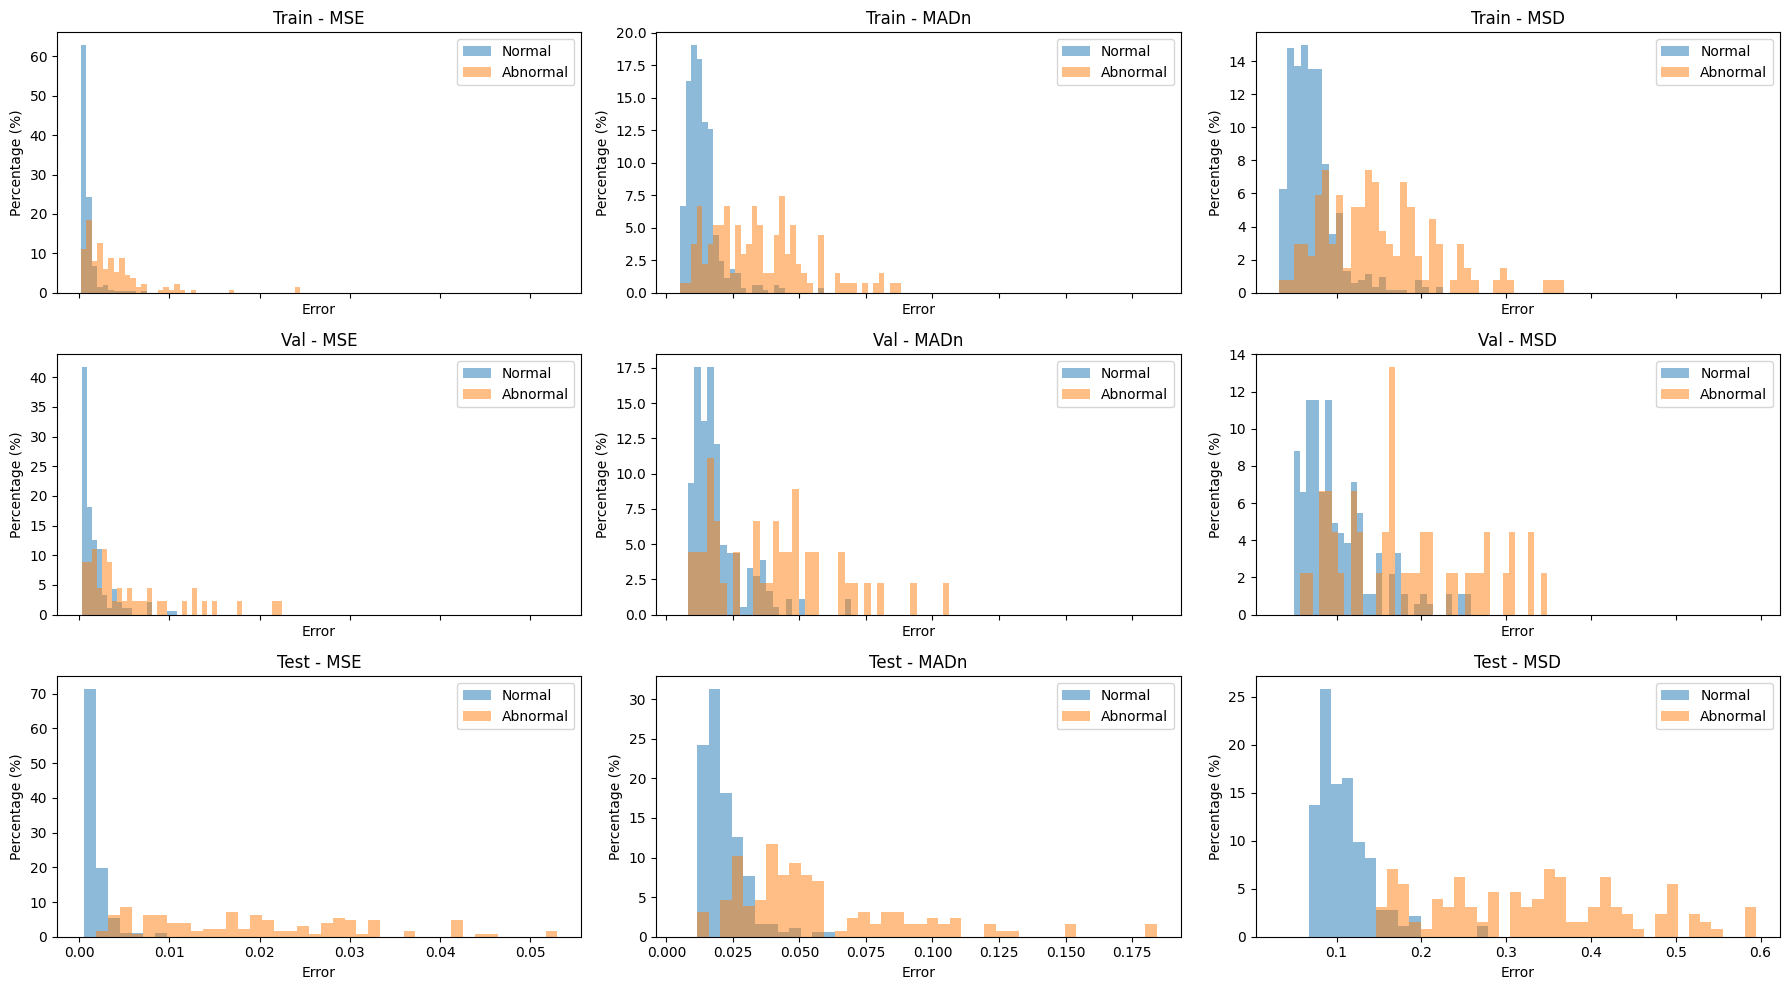

In [86]:
import numpy as np
import matplotlib.pyplot as plt

error_functions = {
    "MSE": vector_mean_squared_error,
    "MADn": vector_mean_absolute_deviation,
    "MSD": vector_mean_standard_deviation
}
dataset_configs = [
    ("Train", image_df["partition"] == "train"),
    ("Val", image_df["partition"] == "val"),
    ("Test",  image_df["partition"] == "test")
]

# Tính error nếu chưa có
for name, func in error_functions.items():
    if name not in image_df.columns:
        image_df[name] = compute_error_once(image_df, func)

fig, axes = plt.subplots(
    len(dataset_configs), 3,
    figsize=(18, 10),
    sharey=False,
    sharex='col'
)

for row_idx, (dataset_name, dataset_mask) in enumerate(dataset_configs):

    df_subset = image_df[dataset_mask]

    for col_idx, error_name in enumerate(error_functions.keys()):

        ax = axes[row_idx, col_idx]

        normal = df_subset.loc[
            df_subset["is_abnormal"] == 0,
            error_name
        ]

        abnormal = df_subset.loc[
            df_subset["is_abnormal"] == 1,
            error_name
        ]

        # dùng chung bins
        bins = np.histogram_bin_edges(
            np.concatenate([normal, abnormal]),
            bins=40
        )

        # histogram theo %
        weights_normal = (
            np.ones(len(normal)) * 100 / len(normal)
            if len(normal) > 0 else None
        )

        weights_abnormal = (
            np.ones(len(abnormal)) * 100 / len(abnormal)
            if len(abnormal) > 0 else None
        )

        ax.hist(
            normal,
            bins=bins,
            weights=weights_normal,
            alpha=0.5,
            label="Normal"
        )

        ax.hist(
            abnormal,
            bins=bins,
            weights=weights_abnormal,
            alpha=0.5,
            label="Abnormal"
        )

        ax.set_title(f"{dataset_name} - {error_name}")
        ax.set_xlabel("Error")
        ax.set_ylabel("Percentage (%)")
        ax.legend()

plt.tight_layout()
plt.show()


In [87]:
results_df = run_threshold_experiments(
    image_df,
    error_functions,
    alphas=np.arange(1.5, 4.5, 0.5)
)


ERROR FUNCTION: MSE
  alpha=1.50 → F1=0.5345, Acc=0.7621
  alpha=2.00 → F1=0.5825, Acc=0.8106
  alpha=2.50 → F1=0.5510, Acc=0.8062
  alpha=3.00 → F1=0.4719, Acc=0.7930
  alpha=3.50 → F1=0.4762, Acc=0.8062
  alpha=4.00 → F1=0.5063, Acc=0.8282

ERROR FUNCTION: MADn
  alpha=1.50 → F1=0.5042, Acc=0.7401
  alpha=2.00 → F1=0.5421, Acc=0.7841
  alpha=2.50 → F1=0.5545, Acc=0.8018
  alpha=3.00 → F1=0.5895, Acc=0.8282
  alpha=3.50 → F1=0.6024, Acc=0.8546
  alpha=4.00 → F1=0.6154, Acc=0.8678

ERROR FUNCTION: MSD
  alpha=1.50 → F1=0.5037, Acc=0.7048
  alpha=2.00 → F1=0.5472, Acc=0.7885
  alpha=2.50 → F1=0.5686, Acc=0.8062
  alpha=3.00 → F1=0.5895, Acc=0.8282
  alpha=3.50 → F1=0.5195, Acc=0.8370
  alpha=4.00 → F1=0.4932, Acc=0.8370


In [88]:
print("-------------- Best in f1 --------------")
print(results_df.sort_values("f1", ascending=False).iloc[0])

print("-------------- Best in accuracy --------------")
print(results_df.sort_values("accuracy", ascending=False).iloc[0])

print("-------------- Compare f1 of each error function --------------")
print(
    results_df.groupby("error_function")["f1"]
    .agg(["mean", "max", "std"])
    .sort_values("max", ascending=False)
)

print("-------------- Which alpha is the best? --------------")
print(
    results_df.groupby("alpha")["f1"]
    .mean()
    .sort_values(ascending=False)
)

print("-------------- Which alpha is the best in each metric? --------------")
best_alphas = (results_df
        .sort_values("f1", ascending=False)  # sort toàn bộ trước
        .groupby("error_function", as_index=False)
        .first()  # lấy row có f1 cao nhất mỗi group
        .sort_values("f1", ascending=False)  # sort lại để so sánh giữa các error function
              )
print(best_alphas)

-------------- Best in f1 --------------
error_function        MADn
alpha                  4.0
mean              0.013514
std               0.006353
threshold_min    -0.011897
threshold_max     0.038924
accuracy          0.867841
f1                0.615385
precision         0.727273
recall            0.533333
r2                0.168498
Name: 11, dtype: object
-------------- Best in accuracy --------------
error_function        MADn
alpha                  4.0
mean              0.013514
std               0.006353
threshold_min    -0.011897
threshold_max     0.038924
accuracy          0.867841
f1                0.615385
precision         0.727273
recall            0.533333
r2                0.168498
Name: 11, dtype: object
-------------- Compare f1 of each error function --------------
                    mean       max       std
error_function                              
MADn            0.567997  0.615385  0.041993
MSD             0.536934  0.589474  0.037936
MSE             0.520410  

## MSE

============================================================
FIXED ALPHA EVALUATION (alpha=2.0) MSE
============================================================

Thresholds: min=-0.0013, max=0.0032

============================================================
CLASSIFICATION RESULTS
============================================================

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            164             18
True Abnormal            6            122

Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.90      0.93       182
    Abnormal       0.87      0.95      0.91       128

    accuracy                           0.92       310
   macro avg       0.92      0.93      0.92       310
weighted avg       0.93      0.92      0.92       310


Metrics:
  accuracy: 0.9226
  f1: 0.9104
  precision: 0.8714
  recall: 0.9531
  r2: 0.6806

============================================================
PER-ABNORMAL PERFORMANCE
============================================================
  dominant_abnormal  count  accuracy  precision  recall  f1_score  \
0            Normal    182    0.9011        0.0  0.0000    0.0000   
1      Random Patch     28    1.0000        1.0  1.0000    1.0000   
2             Noise     26    0.9231        1.0  0.9231    0.9600   
3     Abrupt Change     22    1.0000        1.0  1.0000    1.0000   
4    Sensor Failure     20    0.8000        1.0  0.8000    0.8889   
5      Signal Drift     20    1.0000        1.0  1.0000    1.0000   
6       Unknown Gas     12    1.0000        1.0  1.0000    1.0000   

MSD:
============================================================
FIXED ALPHA EVALUATION (alpha=2.0)
============================================================

Thresholds: min=0.0180, max=0.1410

============================================================
CLASSIFICATION RESULTS
============================================================

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            137             45
True Abnormal            2            126

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.75      0.85       182
    Abnormal       0.74      0.98      0.84       128

    accuracy                           0.85       310
   macro avg       0.86      0.87      0.85       310
weighted avg       0.88      0.85      0.85       310


Metrics:
  accuracy: 0.8484
  f1: 0.8428
  precision: 0.7368
  recall: 0.9844
  r2: 0.3746

============================================================
PER-ABNORMAL PERFORMANCE
============================================================
  dominant_abnormal  count  accuracy  precision  recall  f1_score  \
0            Normal    182    0.7527        0.0     0.0    0.0000   
1      Random Patch     28    1.0000        1.0     1.0    1.0000   
2             Noise     26    1.0000        1.0     1.0    1.0000   
3     Abrupt Change     22    1.0000        1.0     1.0    1.0000   
4    Sensor Failure     20    0.9000        1.0     0.9    0.9474   
5      Signal Drift     20    1.0000        1.0     1.0    1.0000   
6       Unknown Gas     12    1.0000        1.0     1.0    1.0000   
NÊN :
Abnormal Type	Samples	Detected	Missed	Detection Rate (%)
Random Patch	28	28	0	100.00
Noise	26	24	2	92.31
Abrupt Change	22	22	0	100.00
Sensor Failure	20	16	4	80.00
Signal Drift	20	20	0	100.00
Unknown Gas	12	12	0	100.00

FIXED ALPHA EVALUATION (alpha=1.5) MSD
============================================================

Thresholds: min=-0.0011, max=0.0045

============================================================
CLASSIFICATION RESULTS
============================================================

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            164             18
True Abnormal            4            124

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.90      0.94       182
    Abnormal       0.87      0.97      0.92       128

    accuracy                           0.93       310
   macro avg       0.92      0.93      0.93       310
weighted avg       0.93      0.93      0.93       310


Metrics:
  accuracy: 0.9290
  f1: 0.9185
  precision: 0.8732
  recall: 0.9688
  r2: 0.7072

============================================================
PER-ABNORMAL PERFORMANCE
============================================================
  dominant_abnormal  count  accuracy  precision  recall  f1_score  \
0            Normal    182    0.9011        0.0  0.0000    0.0000   
1      Random Patch     28    1.0000        1.0  1.0000    1.0000   
2             Noise     26    0.9231        1.0  0.9231    0.9600   
3     Abrupt Change     22    0.9091        1.0  0.9091    0.9524   
4    Sensor Failure     20    1.0000        1.0  1.0000    1.0000   
5      Signal Drift     20    1.0000        1.0  1.0000    1.0000   
6       Unknown Gas     12    1.0000        1.0  1.0000    1.0000   

   abnormal_rate  predicted_abnormal_rate  
0            0.0                   0.0989  
1            1.0                   1.0000  
2            1.0                   0.9231  
3            1.0                   0.9091  
4            1.0                   1.0000  
5            1.0                   1.0000  
6            1.0                   1.0000  
MADn:

============================================================
FIXED ALPHA EVALUATION (alpha=1.5)
============================================================

Thresholds: min=0.0035, max=0.0337

============================================================
CLASSIFICATION RESULTS
============================================================

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            151             31
True Abnormal           24            104

Classification Report:
              precision    recall  f1-score   support

      Normal       0.86      0.83      0.85       182
    Abnormal       0.77      0.81      0.79       128

    accuracy                           0.82       310
   macro avg       0.82      0.82      0.82       310
weighted avg       0.82      0.82      0.82       310


Metrics:
  accuracy: 0.8226
  f1: 0.7909
  precision: 0.7704
  recall: 0.8125
  r2: 0.2681

============================================================
PER-ABNORMAL PERFORMANCE
============================================================
  dominant_abnormal  count  accuracy  precision  recall  f1_score  \
0            Normal    182    0.8297        0.0  0.0000    0.0000   
1      Random Patch     28    1.0000        1.0  1.0000    1.0000   
2             Noise     26    0.7692        1.0  0.7692    0.8696   
3     Abrupt Change     22    0.8182        1.0  0.8182    0.9000   
4    Sensor Failure     20    0.4000        1.0  0.4000    0.5714   
5      Signal Drift     20    0.9000        1.0  0.9000    0.9474   
6       Unknown Gas     12    1.0000        1.0  1.0000    1.0000   

   abnormal_rate  predicted_abnormal_rate  
0            0.0                   0.1703  
1            1.0                   1.0000  
2            1.0                   0.7692  
3            1.0                   0.8182  
4            1.0                   0.4000  
5            1.0                   0.9000  
MSD:
============================================================
FIXED ALPHA EVALUATION (alpha=1.5)
============================================================

Thresholds: min=0.0317, max=0.1658

============================================================
CLASSIFICATION RESULTS
============================================================

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            155             27
True Abnormal            2            126

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.85      0.91       182
    Abnormal       0.82      0.98      0.90       128

    accuracy                           0.91       310
   macro avg       0.91      0.92      0.91       310
weighted avg       0.92      0.91      0.91       310


Metrics:
  accuracy: 0.9065
  f1: 0.8968
  precision: 0.8235
  recall: 0.9844
  r2: 0.6141

============================================================
PER-ABNORMAL PERFORMANCE
============================================================
  dominant_abnormal  count  accuracy  precision  recall  f1_score  \
0            Normal    182    0.8516        0.0     0.0    0.0000   
1      Random Patch     28    1.0000        1.0     1.0    1.0000   
2             Noise     26    1.0000        1.0     1.0    1.0000   
3     Abrupt Change     22    1.0000        1.0     1.0    1.0000   
4    Sensor Failure     20    0.9000        1.0     0.9    0.9474   
5      Signal Drift     20    1.0000        1.0     1.0    1.0000   
6       Unknown Gas     12    1.0000        1.0     1.0    1.0000   

   abnormal_rate  predicted_abnormal_rate  
0            0.0                   0.1484  
1            1.0                   1.0000  
2            1.0                   1.0000  
3            1.0                   1.0000  
4            1.0                   0.9000  
5            1.0                   1.0000  
6            1.0                   1.0000 


FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=-0.0018, max=0.0034

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            169             13
True Abnormal            2            126

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.93      0.96       182
    Abnormal       0.91      0.98      0.94       128

    accuracy                           0.95       310
   macro avg       0.95      0.96      0.95       310
weighted avg       0.95      0.95      0.95       310


Metrics:
  accuracy: 0.9516
  f1: 0.9438
  precision: 0.9065
  recall: 0.9844
  r2: 0.8004

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  correct  wrong  accuracy  precision  recall  \
0            Normal    182      169     13    0.9286        0.0     0.0   
1      Random Patch     28       28      0    1.0000        1.0     1.0   
2             Noise     26       26      0    1.0000        1.0   

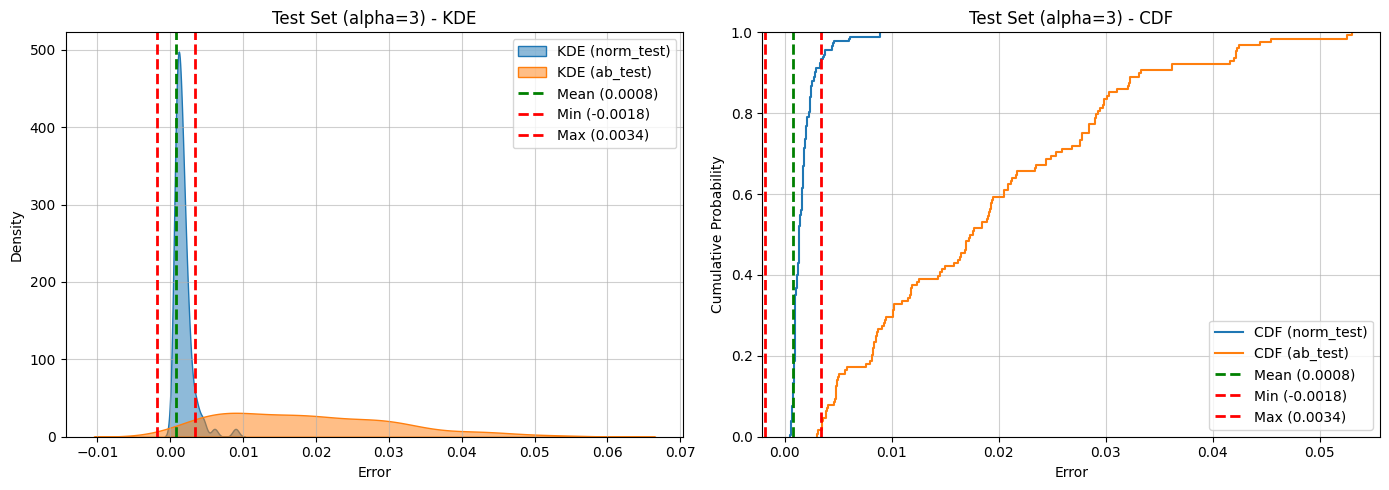

In [113]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_squared_error,
    alpha=3,
    plot=True
)


FIXED ALPHA EVALUATION (alpha=2.0)

Thresholds: min=-0.0009, max=0.0026

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            160             22
True Abnormal            0            128

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.88      0.94       182
    Abnormal       0.85      1.00      0.92       128

    accuracy                           0.93       310
   macro avg       0.93      0.94      0.93       310
weighted avg       0.94      0.93      0.93       310


Metrics:
  accuracy: 0.9290
  f1: 0.9209
  precision: 0.8533
  recall: 1.0000
  r2: 0.7072

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  correct  wrong  accuracy  precision  recall  \
0            Normal    182      160     22    0.8791        0.0     0.0   
1      Random Patch     28       28      0    1.0000        1.0     1.0   
2             Noise     26       26      0    1.0000        1.0 

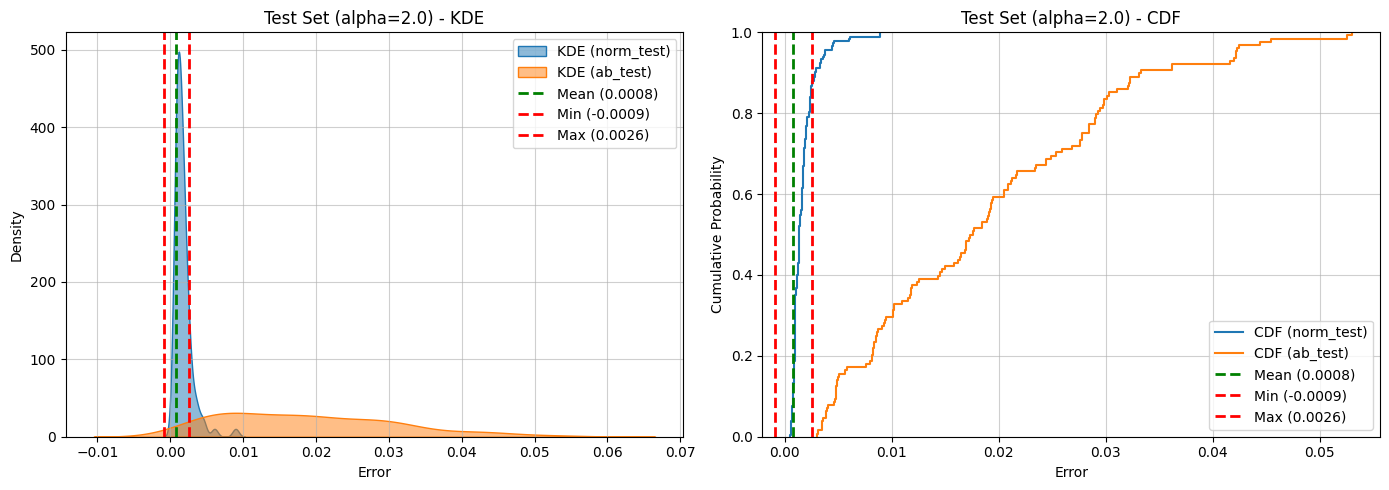

In [97]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_squared_error,
    alpha=best_alphas.loc[best_alphas['error_function'] == 'MSE', 'alpha'].values[0],
    plot=True
)

In [16]:
# x_combined = np.concatenate((x_test_normal, x_test_abnormal), axis=0)
# y_combined_co2 = np.concatenate((y_test_co2, y_abnormal_co2), axis=0)
# y_combined_ethylene = np.concatenate((y_test_ethylene, y_abnormal_ethylene), axis=0)


## MADn


FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=-0.0055, max=0.0326

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            170             12
True Abnormal           28            100

Classification Report:
              precision    recall  f1-score   support

      Normal       0.86      0.93      0.89       182
    Abnormal       0.89      0.78      0.83       128

    accuracy                           0.87       310
   macro avg       0.88      0.86      0.86       310
weighted avg       0.87      0.87      0.87       310


Metrics:
  accuracy: 0.8710
  f1: 0.8333
  precision: 0.8929
  recall: 0.7812
  r2: 0.4677

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  correct  wrong  accuracy  precision  recall  \
0            Normal    182      170     12    0.9341        0.0  0.0000   
1      Random Patch     28       28      0    1.0000        1.0  1.0000   
2             Noise     26       18      8    0.6923        1.0  0

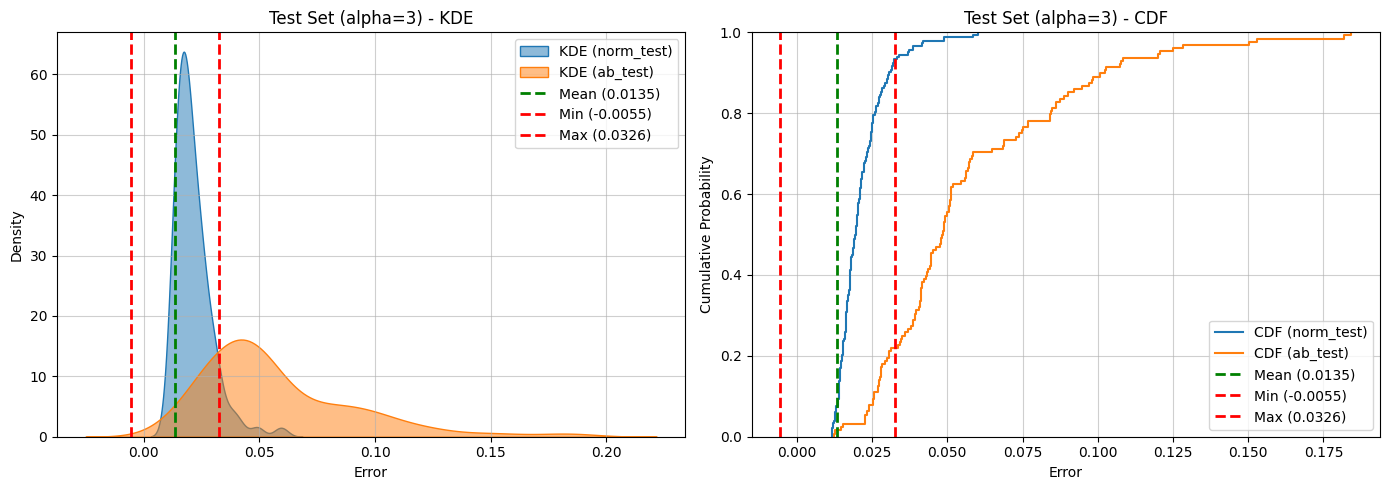

In [118]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_absolute_deviation,
    alpha=3,
    plot=True
)


FIXED ALPHA EVALUATION (alpha=4.0)

Thresholds: min=-0.0119, max=0.0389

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            176              6
True Abnormal           37             91

Classification Report:
              precision    recall  f1-score   support

      Normal       0.83      0.97      0.89       182
    Abnormal       0.94      0.71      0.81       128

    accuracy                           0.86       310
   macro avg       0.88      0.84      0.85       310
weighted avg       0.87      0.86      0.86       310


Metrics:
  accuracy: 0.8613
  f1: 0.8089
  precision: 0.9381
  recall: 0.7109
  r2: 0.4278

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  correct  wrong  accuracy  precision  recall  \
0            Normal    182      176      6    0.9670        0.0  0.0000   
1      Random Patch     28       25      3    0.8929        1.0  0.8929   
2             Noise     26       18      8    0.6923        1.0 

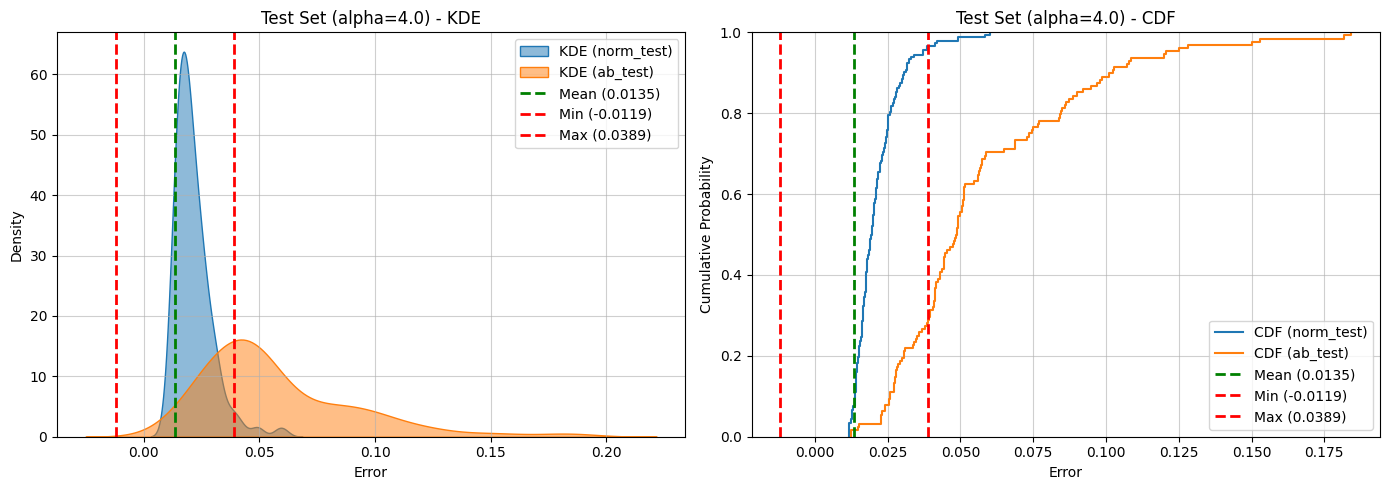

In [98]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_absolute_deviation,
    alpha=best_alphas.loc[best_alphas['error_function'] == 'MADn', 'alpha'].values[0],
    plot=True
)

## MSD


FIXED ALPHA EVALUATION (alpha=3)

Thresholds: min=-0.0158, max=0.1590

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            169             13
True Abnormal            4            124

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.93      0.95       182
    Abnormal       0.91      0.97      0.94       128

    accuracy                           0.95       310
   macro avg       0.94      0.95      0.94       310
weighted avg       0.95      0.95      0.95       310


Metrics:
  accuracy: 0.9452
  f1: 0.9358
  precision: 0.9051
  recall: 0.9688
  r2: 0.7738

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  correct  wrong  accuracy  precision  recall  \
0            Normal    182      169     13    0.9286        0.0  0.0000   
1      Random Patch     28       28      0    1.0000        1.0  1.0000   
2             Noise     26       26      0    1.0000        1.0  1

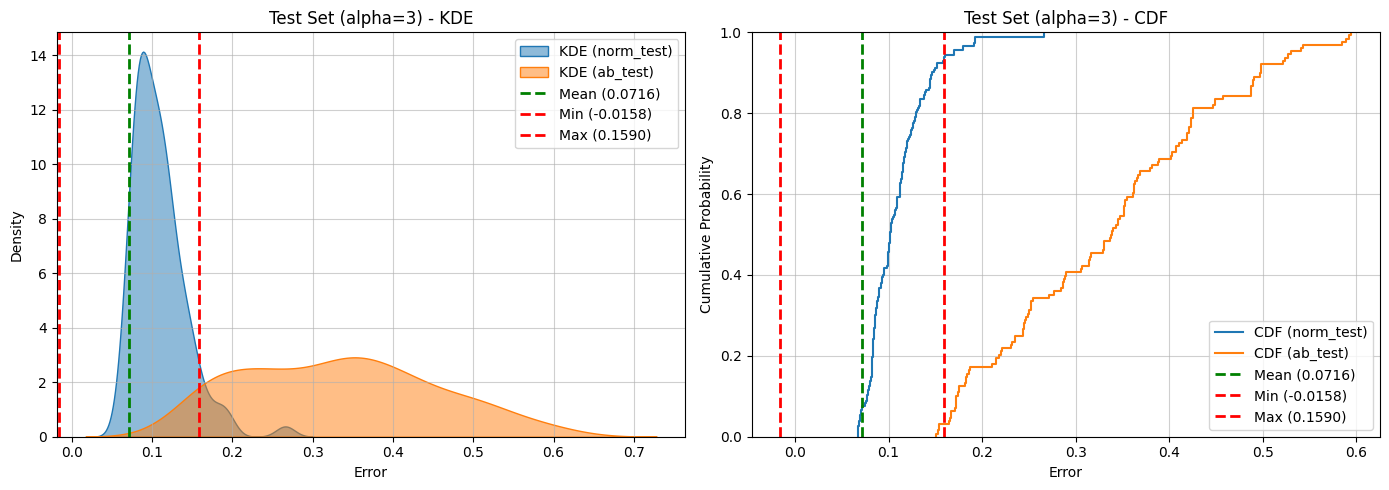

In [108]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_standard_deviation,
    alpha=3,
    plot=True
)


FIXED ALPHA EVALUATION (alpha=3.0)

Thresholds: min=-0.0158, max=0.1590

CLASSIFICATION RESULTS

Confusion Matrix:
               Pred Normal  Pred Abnormal
True Normal            169             13
True Abnormal            4            124

Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.93      0.95       182
    Abnormal       0.91      0.97      0.94       128

    accuracy                           0.95       310
   macro avg       0.94      0.95      0.94       310
weighted avg       0.95      0.95      0.95       310


Metrics:
  accuracy: 0.9452
  f1: 0.9358
  precision: 0.9051
  recall: 0.9688
  r2: 0.7738

PER-ABNORMAL PERFORMANCE
  dominant_abnormal  count  correct  wrong  accuracy  precision  recall  \
0            Normal    182      169     13    0.9286        0.0  0.0000   
1      Random Patch     28       28      0    1.0000        1.0  1.0000   
2             Noise     26       26      0    1.0000        1.0 

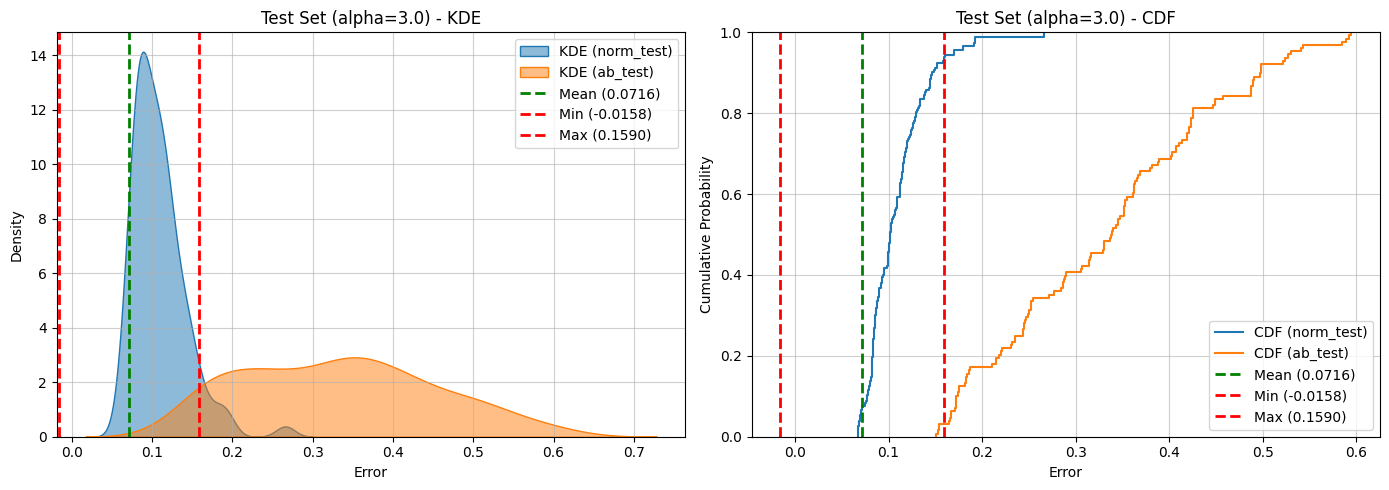

In [99]:
_ = evaluate_with_fixed_alpha(
    image_df,
    vector_mean_standard_deviation,
    alpha=best_alphas.loc[best_alphas['error_function'] == 'MSD', 'alpha'].values[0],
    plot=True
)

Confusion Matrix  Isolation Forest
[[ 96  86]
 [  2 126]]

Classification Report
              precision    recall  f1-score   support

      Normal       0.98      0.53      0.69       182
    Abnormal       0.59      0.98      0.74       128

    accuracy                           0.72       310
   macro avg       0.79      0.76      0.71       310
weighted avg       0.82      0.72      0.71       310

Accuracy : 0.7161290322580646
Precision: 0.5943396226415094
Recall   : 0.984375
F1-score : 0.7411764705882353

One class SVM
(540, 16384) (310, 16384)
[[119  63]
 [  0 128]]
              precision    recall  f1-score   support

      Normal       1.00      0.65      0.79       182
    Abnormal       0.67      1.00      0.80       128

    accuracy                           0.80       310
   macro avg       0.84      0.83      0.80       310
weighted avg       0.86      0.80      0.80       310


## Visualize error space

In [100]:
# ============================
# Chuyển ảnh -> vector cho IsolationForest
# ============================

X_train_if = X_train_moi.reshape(
    X_train_moi.shape[0],
    -1
)

X_test_if = X_test_moi.reshape(
    X_test_moi.shape[0],
    -1
)


print(X_train_if.shape)
print(X_test_if.shape)


# ============================
# Train Isolation Forest
# ============================

from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    n_estimators=200,
    contamination=0.2,
    random_state=42
)

iso.fit(X_train_if)

(540, 16384)
(310, 16384)


IsolationForest(contamination=0.2, n_estimators=200, random_state=42)

In [101]:
pred_if = iso.predict(X_test_if)

y_pred_if = np.where(
    pred_if == 1,
    0,   # Normal
    1    # Abnormal
)

In [102]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred_if))

print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred_if,
        target_names=["Normal","Abnormal"]
    )
)

print("Accuracy :", accuracy_score(y_test,y_pred_if))
print("Precision:", precision_score(y_test,y_pred_if))
print("Recall   :", recall_score(y_test,y_pred_if))
print("F1-score :", f1_score(y_test,y_pred_if))

Confusion Matrix
[[ 96  86]
 [  2 126]]

Classification Report
              precision    recall  f1-score   support

      Normal       0.98      0.53      0.69       182
    Abnormal       0.59      0.98      0.74       128

    accuracy                           0.72       310
   macro avg       0.79      0.76      0.71       310
weighted avg       0.82      0.72      0.71       310

Accuracy : 0.7161290322580646
Precision: 0.5943396226415094
Recall   : 0.984375
F1-score : 0.7411764705882353


In [103]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
X_train = X_train_normal.reshape(len(X_train_normal), -1)
X_test = X_test.reshape(len(X_test), -1)

print(X_train.shape, X_test.shape)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
oc_svm = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.05   # tỷ lệ anomaly mong đợi (5%)
)

oc_svm.fit(X_train_scaled)
y_pred_train = oc_svm.predict(X_train_scaled)
y_pred_test = oc_svm.predict(X_test_scaled)
y_pred_test_binary = np.where(y_pred_test == 1, 0, 1)
print(confusion_matrix(y_test, y_pred_test_binary))

print(classification_report(
    y_test,
    y_pred_test_binary,
    target_names=['Normal', 'Abnormal']
))

(540, 16384) (310, 16384)
[[119  63]
 [  0 128]]
              precision    recall  f1-score   support

      Normal       1.00      0.65      0.79       182
    Abnormal       0.67      1.00      0.80       128

    accuracy                           0.80       310
   macro avg       0.84      0.83      0.80       310
weighted avg       0.86      0.80      0.80       310



In [105]:
#################import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import confusion_matrix, classification_report

# =========================
# 1. Flatten dữ liệu
# =========================

X_train = X_train_normal.reshape(len(X_train_normal), -1)
X_test = X_test.reshape(len(X_test), -1)

print("Shapes:", X_train.shape, X_test.shape)

# =========================
# 2. Chuẩn hóa dữ liệu
# =========================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =========================
# 3. Train LOF (normal only)
# =========================

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    novelty=True   # QUAN TRỌNG để predict test set
)

lof.fit(X_train_scaled)

# =========================
# 4. Dự đoán
# =========================

# Train prediction (optional)
y_pred_train = lof.predict(X_train_scaled)
y_pred_train_binary = np.where(y_pred_train == -1, 1, 0)

# Test prediction
y_pred_test = lof.predict(X_test_scaled)
y_pred_test_binary = np.where(y_pred_test == -1, 1, 0)

# =========================
# 5. Đánh giá
# =========================

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test_binary))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_test_binary,
        target_names=['Normal', 'Abnormal']
    )
)

Shapes: (540, 16384) (310, 16384)
Confusion Matrix:
[[145  37]
 [  4 124]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.80      0.88       182
    Abnormal       0.77      0.97      0.86       128

    accuracy                           0.87       310
   macro avg       0.87      0.88      0.87       310
weighted avg       0.89      0.87      0.87       310



Bắt đầu vẽ 3 biểu đồ không gian sai số 2D...


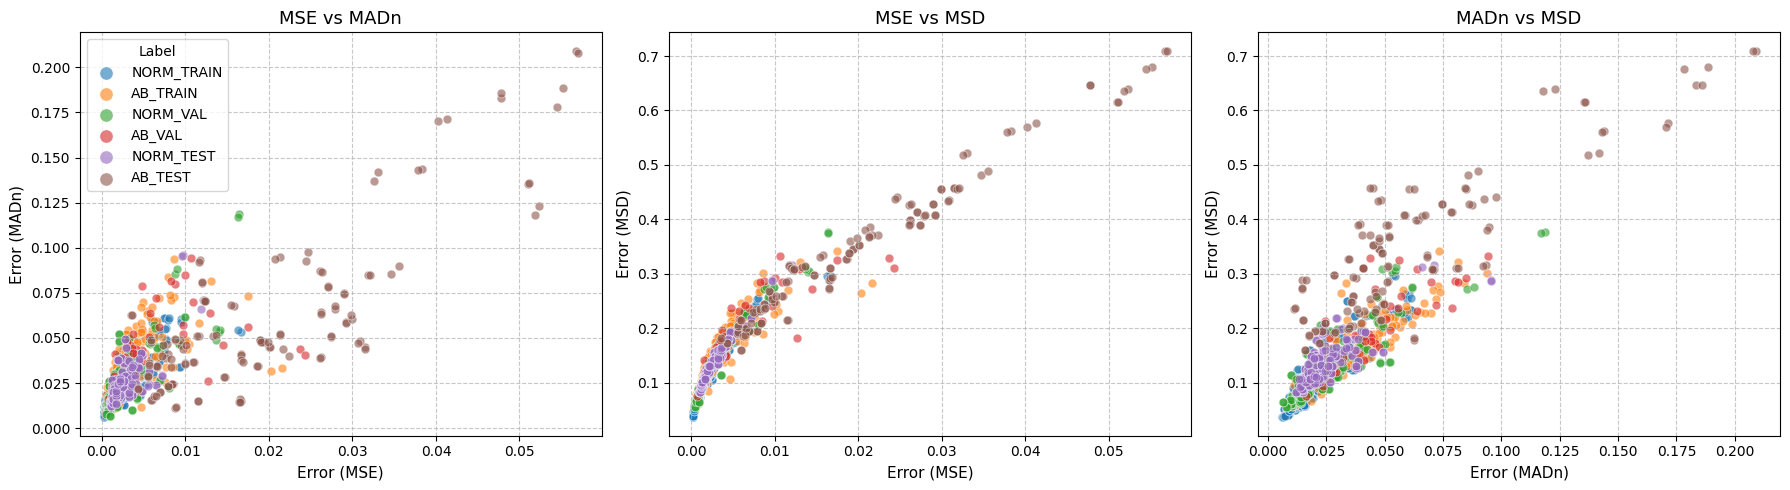

Hoàn thành trực quan hóa.


In [31]:
def visualize_error_space_2d(image_df):
    """
    Trực quan hóa không gian sai số 2D với 3 cặp chỉ số sai số, 
    vẽ thành 3 biểu đồ scatter plot nằm ngang.

    Args:
        image_df (pd.DataFrame): DataFrame chứa cột 'label'.
        mse_list (list/np.ndarray): List các giá trị sai số MSE.
        madn_list (list/np.ndarray): List các giá trị sai số MADn.
        msd_list (list/np.ndarray): List các giá trị sai số MSD.
    """
    
    # 1. Chuẩn bị DataFrame cho việc vẽ biểu đồ
    error_df = image_df.loc[:, ['MSE', 'MADn', 'MSD', 'label']]
    error_df = error_df.replace([np.inf, -np.inf], np.nan)
    error_df = error_df.dropna()
    # 2. Định nghĩa các cặp trục và nhãn
    plot_configs = [
        {'x_col': 'MSE', 'y_col': 'MADn', 'title': 'MSE vs MADn'},
        {'x_col': 'MSE', 'y_col': 'MSD', 'title': 'MSE vs MSD'},
        {'x_col': 'MADn', 'y_col': 'MSD', 'title': 'MADn vs MSD'},
    ]
    
    # Lấy các nhãn và tạo bảng màu nhất quán
    unique_labels = error_df['label'].unique()
    palette = sns.color_palette("tab10", n_colors=len(unique_labels))
    color_map = dict(zip(unique_labels, palette))
    
    
    # 3. Khởi tạo Figure với 3 Subplots nằm ngang
    fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # 1 hàng, 3 cột
    
    print("Bắt đầu vẽ 3 biểu đồ không gian sai số 2D...")

    # 4. Vẽ từng biểu đồ
    for i, config in enumerate(plot_configs):
        ax = axes[i]
        x_col = config['x_col']
        y_col = config['y_col']

        # Vẽ từng nhãn riêng lẻ để sử dụng màu và tạo legend chính xác
        for label in unique_labels:
            df_subset = error_df[error_df['label'] == label]
            
            ax.scatter(
                df_subset[x_col],
                df_subset[y_col],
                color=color_map[label],
                label=label.upper(),
                alpha=0.6,
                s=40, # Kích thước điểm
                edgecolors='w', # Viền trắng
                linewidths=0.5
            )

        # Cài đặt nhãn trục và tiêu đề
        ax.set_xlabel(f'Error ({x_col})', fontsize=11)
        ax.set_ylabel(f'Error ({y_col})', fontsize=11)
        ax.set_title(config['title'], fontsize=13)
        ax.grid(True, linestyle='--', alpha=0.7)
        
        # Chỉ vẽ legend cho biểu đồ đầu tiên để tránh dư thừa, 
        # do màu sắc đã nhất quán.
        if i == 0:
            ax.legend(title='Label', loc='best', markerscale=1.5)
        
    # 5. Tối ưu layout và hiển thị
    plt.tight_layout()
    plt.show()
    print("Hoàn thành trực quan hóa.")

image_df['MSE'] = compute_error_once(image_df, vector_mean_squared_error)
image_df['MADn'] = compute_error_once(image_df, vector_mean_absolute_deviation)
image_df['MSD'] = compute_error_once(image_df, vector_mean_standard_deviation)

visualize_error_space_2d(image_df)

# Benchmark

In [20]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.svm import OneClassSVM, SVC
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from xgboost import XGBClassifier


def prepare_data(image_df):
    """
    Input:
        image_df có:
            - is_abnormal
            - partition = train / val / test
            - MSE, MADn, MSD
            - latent_vector (optional)

    Output:
        X_train, y_train
        X_val, y_val
        X_test, y_test
        scaler
    """

    df = image_df.copy()

    # ==================================================
    # Feature matrix
    # ==================================================

    base = df[['MSE', 'MADn', 'MSD']].values

    # Nếu muốn dùng latent vector:
    # latent = np.vstack(df['latent_vector'].values)
    # X = np.hstack([base, latent]).astype(np.float32)

    X = base.astype(np.float32)

    y = df['is_abnormal'].values.astype(int)

    # ==================================================
    # Clean
    # ==================================================

    X = np.nan_to_num(
        X,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    # ==================================================
    # Split theo partition
    # ==================================================

    train_mask = df['partition'] == 'train'
    val_mask   = df['partition'] == 'val'
    test_mask  = df['partition'] == 'test'

    X_train = X[train_mask]
    y_train = y[train_mask]

    X_val = X[val_mask]
    y_val = y[val_mask]

    X_test = X[test_mask]
    y_test = y[test_mask]

    # ==================================================
    # Scale (fit trên train)
    # ==================================================

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    # ==================================================
    # Info
    # ==================================================

    print(f"Train: {X_train.shape}, abnormal={y_train.mean():.3f}")
    print(f"Val  : {X_val.shape}, abnormal={y_val.mean():.3f}")
    print(f"Test : {X_test.shape}, abnormal={y_test.mean():.3f}")

    return (
        X_train, y_train,
        X_val, y_val,
        X_test, y_test
    )
    
def build_model(model_type, params):

    if model_type == "ocsvm":
        return OneClassSVM(kernel='rbf', **params)

    elif model_type == "isolation_forest":
        return IsolationForest(random_state=42, **params)
    
    elif model_type == "random_forest":
        return RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            **params
    )
    elif model_type == "svm":
        return SVC(
            probability=True,
            class_weight="balanced",
            **params
        )
    elif model_type == "xgboost":
        return XGBClassifier(
            scale_pos_weight=params.get("scale_pos_weight", 1),
            eval_metric='logloss',
            **params
        )
    elif model_type == "mlp":
        return MLPClassifier(max_iter=300, **params)

    else:
        raise ValueError("Unsupported model")
        
def train(model, model_type, X_train, y_train):

    if model_type in ["ocsvm"]:
        # anomaly (normal only)
        X_train = X_train[y_train == 0]
        model.fit(X_train)

    elif model_type in ["isolation_forest"]:
        # unsupervised
        model.fit(X_train)

    else:
        # supervised
        model.fit(X_train, y_train)

    return model
    
def predict_and_score(model, model_type, X):

    if model_type == "ocsvm":
        preds = model.predict(X)  # 1 / -1
        scores = -model.decision_function(X)

        y_pred = np.where(preds == 1, 0, 1)

    elif model_type == "isolation_forest":
        preds = model.predict(X)
        scores = -model.score_samples(X)

        y_pred = np.where(preds == 1, 0, 1)

    elif model_type in ["random_forest", "svm", "xgboost", "mlp"]:

        prob = model.predict_proba(X)

        if prob.shape[1] == 1:
            scores = np.zeros(len(X))
            y_pred = np.zeros(len(X))
        else:
            scores = prob[:, 1]
            y_pred = (scores > 0.5).astype(int)

    else:
        raise ValueError("Unsupported model")

    return y_pred, scores
    
from sklearn.metrics import average_precision_score, average_precision_score, f1_score, accuracy_score
import pandas as pd


def evaluate(model, model_type, X, y, name="Set"):

    y_pred, scores = predict_and_score(model, model_type, X)

    # ===== Metrics =====
    acc = accuracy_score(y, y_pred)

    pr_auc = None
    f1 = None

    if len(np.unique(y)) > 1:
        pr_auc = average_precision_score(y, scores)
        f1 = f1_score(y, y_pred)

    # ===== Print =====
    cm = confusion_matrix(y, y_pred, labels=[0, 1])

    print("\n" + "="*50)
    print(f"{name.upper()} - {model_type.upper()}")
    print("="*50)

    print(pd.DataFrame(
        cm,
        index=['True Normal', 'True Abnormal'],
        columns=['Pred Normal', 'Pred Abnormal']
    ))

    print("\nClassification Report:")
    print(classification_report(y, y_pred, target_names=['Normal', 'Abnormal'], zero_division=0))

    print(f"Accuracy: {acc:.4f}")
    print(f"PR-AUC : {pr_auc}")
    print(f"F1-score: {f1}")

    return {
        "acc": acc,
        "pr_auc": pr_auc,
        "f1": f1
    }
    
def evaluate_all(model, model_type,
                 X_train, y_train,
                 X_val, y_val,
                 X_test, y_test):

    results = {}

    results["Train"] = evaluate(model, model_type, X_train, y_train, "Train")
    results["Val"]   = evaluate(model, model_type, X_val, y_val, "Validation")
    results["Test"]  = evaluate(model, model_type, X_test, y_test, "Test")

    return results

import itertools

def grid_search(model_type, param_grid,
                X_train, y_train,
                X_val, y_val):

    import itertools
    from sklearn.metrics import average_precision_score

    keys = list(param_grid.keys())
    combos = list(itertools.product(*param_grid.values()))

    best_score = -np.inf
    best_model = None
    best_params = None

    for values in combos:
        params = dict(zip(keys, values))

        model = build_model(model_type, params)
        model = train(model, model_type, X_train, y_train)

        _, scores = predict_and_score(model, model_type, X_val)

        if len(np.unique(y_val)) < 2:
            continue

        pr_auc = average_precision_score(y_val, scores)

        print(f"{model_type} | {params} → {pr_auc:.4f}")

        if pr_auc > best_score:
            best_score = pr_auc
            best_model = model
            best_params = params

    return best_model, best_params

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def plot_boundary(model, model_type, X_train, y_train, X_val=None, y_val=None):

    pca = PCA(n_components=2)
    X_train_2d = pca.fit_transform(X_train)

    xx, yy = np.meshgrid(
        np.linspace(X_train_2d[:,0].min()-1, X_train_2d[:,0].max()+1, 200),
        np.linspace(X_train_2d[:,1].min()-1, X_train_2d[:,1].max()+1, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_orig = pca.inverse_transform(grid)

    _, scores = predict_and_score(model, model_type, grid_orig)
    Z = scores.reshape(xx.shape)

    plt.figure()
    plt.contourf(xx, yy, Z > 0, alpha=0.3)
    plt.contour(xx, yy, Z, levels=[0])

    plt.scatter(X_train_2d[:,0], X_train_2d[:,1], label="Train")

    if X_val is not None:
        X_val_2d = pca.transform(X_val)
        for label in [0, 1]:
            subset = X_val_2d[y_val == label]
            plt.scatter(subset[:,0], subset[:,1], label=label)

    plt.legend()
    plt.title("Decision Boundary")
    plt.show()


In [21]:
def run_benchmark(X_train, y_train, X_val, y_val, X_test, y_test):
    models_config = {
        "ocsvm": {
            "nu": [0.01, 0.03, 0.05, 0.1],
            "gamma": [1e-4, 1e-3, 1e-2, 1e-1]
        },
        "isolation_forest": {
            "n_estimators": [100, 200],
            "contamination": [0.01, 0.03, 0.05, 0.1],
            "max_samples": ["auto", 0.8]
        },
        "random_forest": {
            "n_estimators": [100, 200],
            "max_depth": [None, 5, 10, 20],
            "min_samples_split": [2, 5]
        },
        "svm": {
            "C": [0.1, 1, 10],
            "gamma": ["scale", 0.01, 0.001],
            "kernel": ["rbf"]
        },
        "xgboost": {
            "n_estimators": [100, 200],
            "max_depth": [3, 5, 7],
            "learning_rate": [0.01, 0.1],
            "subsample": [0.8, 1.0]
        },
        "mlp": {
            "hidden_layer_sizes": [(64,), (128,), (128,64)],
            "alpha": [1e-4, 1e-3],
            "learning_rate_init": [1e-3, 1e-2]
        }
    }
    results_summary = {}

    # =========================================================
    # ===== 1. ML MODELS ======================================
    # =========================================================
    for model_type, grid in models_config.items():

        print("\n" + "="*60)
        print(f"MODEL: {model_type}")
        print("="*60)

        best_model, best_params = grid_search(
            model_type, grid,
            X_train, y_train,
            X_val, y_val
        )

        results = evaluate_all(
            best_model, model_type,
            X_train, y_train,
            X_val, y_val,
            X_test, y_test
        )

        results_summary[model_type] = {
            "params": best_params,
            "metrics": results   # 🔥 lưu full train/val/test
        }
    return results_summary

def print_benchmark(results, sort_by="f1"):

    print("\nFINAL BENCHMARK (TEST SET)")
    print("="*80)

    rows = []

    for model, res in results.items():
        test_metrics = res["metrics"]["Test"]

        rows.append({
            "model": model,
            "acc": test_metrics["acc"],
            "pr_auc": test_metrics["pr_auc"],
            "f1": test_metrics["f1"]
        })

    df = pd.DataFrame(rows)

    df = df.sort_values(by=sort_by, ascending=False)

    print(df.to_string(index=False))


In [22]:
# ===== Prepare =====
X_train, y_train, X_val, y_val, X_test, y_test = prepare_data(image_df)
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

def show_dist(y, name):
    unique, counts = np.unique(y, return_counts=True)
    print(f"{name}:", dict(zip(unique, counts)))

show_dist(y_train, "Train")
show_dist(y_val, "Val")
show_dist(y_test, "Test")

Train: (567, 3), abnormal=0.199
Val  : (197, 3), abnormal=0.198
Test : (205, 3), abnormal=0.200
Train: (567, 3) (567,)
Val  : (197, 3) (197,)
Test : (205, 3) (205,)
Train: {0: 454, 1: 113}
Val: {0: 158, 1: 39}
Test: {0: 164, 1: 41}


In [23]:
results = run_benchmark(
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
)
print_benchmark(results, sort_by="f1")


MODEL: ocsvm
ocsvm | {'nu': 0.01, 'gamma': 0.0001} → 0.4109
ocsvm | {'nu': 0.01, 'gamma': 0.001} → 0.4152
ocsvm | {'nu': 0.01, 'gamma': 0.01} → 0.4103
ocsvm | {'nu': 0.01, 'gamma': 0.1} → 0.3713
ocsvm | {'nu': 0.03, 'gamma': 0.0001} → 0.4253
ocsvm | {'nu': 0.03, 'gamma': 0.001} → 0.4265
ocsvm | {'nu': 0.03, 'gamma': 0.01} → 0.4248
ocsvm | {'nu': 0.03, 'gamma': 0.1} → 0.4141
ocsvm | {'nu': 0.05, 'gamma': 0.0001} → 0.4366
ocsvm | {'nu': 0.05, 'gamma': 0.001} → 0.4367
ocsvm | {'nu': 0.05, 'gamma': 0.01} → 0.4327
ocsvm | {'nu': 0.05, 'gamma': 0.1} → 0.4203
ocsvm | {'nu': 0.1, 'gamma': 0.0001} → 0.4398
ocsvm | {'nu': 0.1, 'gamma': 0.001} → 0.4399
ocsvm | {'nu': 0.1, 'gamma': 0.01} → 0.4394
ocsvm | {'nu': 0.1, 'gamma': 0.1} → 0.4388

TRAIN - OCSVM
               Pred Normal  Pred Abnormal
True Normal            410             44
True Abnormal           50             63

Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      0.90      0.9

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


mlp | {'hidden_layer_sizes': (64,), 'alpha': 0.0001, 'learning_rate_init': 0.001} → 0.8152


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


mlp | {'hidden_layer_sizes': (64,), 'alpha': 0.0001, 'learning_rate_init': 0.01} → 0.6839


...

mlp | {'hidden_layer_sizes': (128,), 'alpha': 0.001, 'learning_rate_init': 0.001} → 0.8051
mlp | {'hidden_layer_sizes': (128,), 'alpha': 0.001, 'learning_rate_init': 0.01} → 0.7293


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


mlp | {'hidden_layer_sizes': (128, 64), 'alpha': 0.0001, 'learning_rate_init': 0.001} → 0.7647
mlp | {'hidden_layer_sizes': (128, 64), 'alpha': 0.0001, 'learning_rate_init': 0.01} → 0.7476


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


mlp | {'hidden_layer_sizes': (128, 64), 'alpha': 0.001, 'learning_rate_init': 0.001} → 0.7788
mlp | {'hidden_layer_sizes': (128, 64), 'alpha': 0.001, 'learning_rate_init': 0.01} → 0.7717

TRAIN - MLP
               Pred Normal  Pred Abnormal
True Normal            446              8
True Abnormal           43             70

Classification Report:
              precision    recall  f1-score   support

      Normal       0.91      0.98      0.95       454
    Abnormal       0.90      0.62      0.73       113

    accuracy                           0.91       567
   macro avg       0.90      0.80      0.84       567
weighted avg       0.91      0.91      0.90       567

Accuracy: 0.9101
PR-AUC : 0.8026774528426813
F1-score: 0.7329842931937173

VALIDATION - MLP
               Pred Normal  Pred Abnormal
True Normal            154              4
True Abnormal           13             26

Classification Report:
              precision    recall  f1-score   support

      Normal       0.92   

# Dynamic threshold

In [24]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import classification_report, confusion_matrix

def calculate_error_only(image_df, cal_error_function):
    """
    Chỉ tính error cho từng sample
    """
    original_images_list = image_df['original_image'].tolist()
    reconstructed_images_list = image_df['reconstructed_image'].tolist()
    
    all_errors = cal_error_function(original_images_list, reconstructed_images_list)
    image_df['error'] = all_errors
    
    return image_df

def train_dynamic_threshold_model(image_df, alpha=0.95):
    """
    Train quantile regression model để học threshold động
    """
    
    # ⚠️ chỉ dùng norm_train
    df_train = image_df[image_df['label'] == 'norm_train']

    X = np.hstack([
        df_train[['MSE', 'MADn', 'MSD']].values,
        np.vstack(df_train['latent_vector'].values)
    ])
    
    # X = df_train[['MSE', 'MADn', 'MSD']].values      
    y = df_train['error'].values

    model = GradientBoostingRegressor(
        loss='quantile',
        alpha=alpha,
        n_estimators=200,
        max_depth=3,
        random_state=42
    )

    model.fit(X, y)

    return model

def predict_dynamic_threshold(image_df, model, margin=0.0):
    """
    Predict label bằng threshold động
    """
    
    X = np.hstack([
        image_df[['MSE', 'MADn', 'MSD']].values,
        np.vstack(image_df['latent_vector'].values)
    ])
    # X = image_df[['MSE', 'MADn', 'MSD']].values      

    # Threshold riêng từng sample
    thresholds = model.predict(X)

    # Classification
    image_df['Predicted_Label'] = np.where(
        image_df['error'] > (thresholds + margin),
        'Abnormal',
        'Normal'
    )

    return image_df, thresholds

def evaluate_dynamic(image_df, log = False):
    cm = confusion_matrix(
        image_df['True_Label'],
        image_df['Predicted_Label'],
        labels=['Normal', 'Abnormal']
    )

    if log:
        print("\n" + "="*50)
        print("DYNAMIC THRESHOLD RESULTS")
        print("="*50)
    
        print("\nConfusion Matrix:")
        print(pd.DataFrame(cm, 
            index=['True Normal', 'True Abnormal'],
            columns=['Pred Normal', 'Pred Abnormal']
        ))
    
        print("\nClassification Report:")
        print(classification_report(
            image_df['True_Label'],
            image_df['Predicted_Label'],
            labels=['Normal', 'Abnormal'],
            zero_division=0
        ))

    return cm

def run_dynamic_threshold_pipeline(image_df, cal_error_function, alpha=0.95, margin=0.0, log = False):
    """
    Pipeline hoàn chỉnh dynamic threshold
    """

    # 1. Tính error
    image_df = calculate_error_only(image_df.copy(), cal_error_function)

    # 2. Train model
    model = train_dynamic_threshold_model(image_df, alpha=alpha)

    # 3. Predict
    image_df, thresholds = predict_dynamic_threshold(image_df, model, margin=margin)

    # 4. Evaluate
    cm = evaluate_dynamic(image_df, log)

    return image_df, thresholds, model

from sklearn.metrics import f1_score

def tune_alpha(image_df, cal_error_function, alphas):
    best_alpha = None
    best_f1 = -1

    for alpha in alphas:
        df, _, _ = run_dynamic_threshold_pipeline(
            image_df.copy(),
            cal_error_function,
            alpha=alpha
        )

        f1 = f1_score(
            df['True_Label'],
            df['Predicted_Label'],
            pos_label='Abnormal'
        )

        print(f"alpha={alpha:.3f} → F1={f1:.4f}")

        if f1 > best_f1:
            best_f1 = f1
            best_alpha = alpha

    print(f"\nBEST alpha = {best_alpha}, F1 = {best_f1:.4f}")
    return best_alpha

In [25]:
def build_model(model_name, params, alpha):
    if model_name == "gbr":
        return GradientBoostingRegressor(
            loss='quantile',
            alpha=alpha,
            random_state=42,
            **params
        )
    
    elif model_name == "rf":
        from sklearn.ensemble import RandomForestRegressor
        # RF không support quantile trực tiếp → dùng mean + scale
        return RandomForestRegressor(
            random_state=42,
            **params
        )
    
    elif model_name == "lgbm":
        from lightgbm import LGBMRegressor
        return LGBMRegressor(
            objective='quantile',
            alpha=alpha,
            random_state=42,
            **params
        )
    
    else:
        raise ValueError(f"Unknown model: {model_name}")

def train_dynamic_model_generic(image_df, model):
    df_train = image_df[image_df['label'] == 'norm_train']

    X = np.hstack([
        df_train[['MSE', 'MADn', 'MSD']].values,
        np.vstack(df_train['latent_vector'].values)
    ])

    # X = df_train[['MSE', 'MADn', 'MSD']].values
    y = df_train['error'].values

    model.fit(X, y)
    return model

from itertools import product
from sklearn.metrics import f1_score

def grid_search_dynamic_threshold(
    image_df,
    cal_error_function,
    model_configs,
    alphas,
    margins
):
    best_config = None
    best_f1 = -1
    results = []

    # Precompute error (IMPORTANT: tránh recompute nhiều lần)
    image_df = calculate_error_only(image_df.copy(), cal_error_function)

    for model_name, param_grid in model_configs.items():
        keys, values = zip(*param_grid.items())

        for param_comb in product(*values):
            params = dict(zip(keys, param_comb))

            for alpha in alphas:
                for margin in margins:

                    try:
                        model = build_model(model_name, params, alpha)

                        trained_model = train_dynamic_model_generic(image_df, model)

                        df_pred, _ = predict_dynamic_threshold(
                            image_df.copy(),
                            trained_model,
                            margin=margin
                        )

                        f1 = f1_score(
                            df_pred['True_Label'],
                            df_pred['Predicted_Label'],
                            pos_label='Abnormal'
                        )

                        config = {
                            "model": model_name,
                            "params": params,
                            "alpha": alpha,
                            "margin": margin,
                            "f1": f1
                        }

                        results.append(config)

                        print(f"{config}")

                        if f1 > best_f1:
                            best_f1 = f1
                            best_config = config

                    except Exception as e:
                        print(f"Skip config due to error: {e}")

    print("\nBEST CONFIG:")
    print(best_config)

    return best_config, pd.DataFrame(results)

def evaluate_best_config(
    image_df,
    cal_error_function,
    best_config,
    results_df=None,
    log=True
):
    """
    Train lại model với best_config và evaluate đầy đủ
    """

    # 1. Copy data + tính error
    df = calculate_error_only(image_df.copy(), cal_error_function)

    # 2. Build model từ best_config
    model = build_model(
        best_config["model"],
        best_config["params"],
        best_config["alpha"]
    )

    # 3. Train
    model = train_dynamic_model_generic(df, model)

    # 4. Predict
    df_pred, thresholds = predict_dynamic_threshold(
        df,
        model,
        margin=best_config["margin"]
    )

    # 5. Evaluate
    cm = evaluate_dynamic(df_pred, log=log)

    # 6. In thêm thông tin best config
    print("\nBEST CONFIG USED:")
    for k, v in best_config.items():
        print(f"{k}: {v}")

    # 7. Optional: phân tích ranking
    if results_df is not None:
        print("\nTOP 5 CONFIGS:")
        display_cols = ["model", "alpha", "margin", "f1"]
        if "params" in results_df.columns:
            display_cols.append("params")

        print(
            results_df
            .sort_values("f1", ascending=False)
            .head(5)[display_cols]
        )

    return df_pred, thresholds, model, cm

In [26]:
def pipeline_dynamic_thres(image_df, cal_error_function, alphas, model_configs, margins):
    # 1. Tune alpha
    # best_alpha = tune_alpha(
    #     image_df,
    #     cal_error_function,
    #     alphas=alphas
    # )
    best_config, results_df = grid_search_dynamic_threshold(
        image_df,
        cal_error_function,
        model_configs,
        alphas,
        margins
    )
    # 2. Run final
    # df_result, thresholds, model = run_dynamic_threshold_pipeline(
    #     image_df,
    #     cal_error_function,
    #     alpha=best_alpha,
    #     margin=0.0,
    #     log=True
    # )
    df_pred, thresholds, model, cm = evaluate_best_config(
        image_df,
        cal_error_function,
        best_config,
        results_df=results_df,
        log=True
    )
    return results_df

In [27]:
model_configs = {
    "gbr": {
        "n_estimators": [20, 50, 100],
        "max_depth": [1, 3],
        "learning_rate": [0.001, 0.05]
    },
    "rf": {
        "n_estimators": [50, 100],
        "max_depth": [None, 5]
    },
    "lgbm": {
        "n_estimators": [20, 50, 100],
        "num_leaves": [16, 32],
        "learning_rate": [0.001, 0.05]
    }
}

alphas = np.arange(0.9, 1-0.01, 0.01)
margins = [0.0, 0.001] # np.arange(0.0, 0.05, 0.01)

## MSE

In [28]:
results_df = pipeline_dynamic_thres(image_df = image_df, 
                       cal_error_function = vector_mean_squared_error,
                       alphas = alphas,
                       model_configs = model_configs,
                       margins = margins)

{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.9, 'margin': 0.0, 'f1': 0.5461689587426326}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.9, 'margin': 0.001, 'f1': 0.549889135254989}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.91, 'margin': 0.0, 'f1': 0.5461689587426326}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.91, 'margin': 0.001, 'f1': 0.5511111111111111}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.92, 'margin': 0.0, 'f1': 0.5454545454545455}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.92, 'margin': 0.001, 'f1': 0.5484633569739952}
{'model': 'gbr', 'params': {'n_estimators': 20, 'max_depth': 1, 'learning_rate': 0.001}, 'alpha': 0.93, 'margin': 0.0, 'f1': 0.

In [29]:
results_df.head(10)

,model,params,alpha,margin,f1
0,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.90,0.000,0.546169
1,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.90,0.001,0.549889
2,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.91,0.000,0.546169
3,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.91,0.001,0.551111
4,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.92,0.000,0.545455
5,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.92,0.001,0.548463
6,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.93,0.000,0.552743
7,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.93,0.001,0.533654
8,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.94,0.000,0.562637
9,gbr,"{'n_estimators': 20, 'max_depth': 1, 'learning...",0.94,0.001,0.544118
